# Magnitude inicial: cada forma de histórico comparada entre geradores

Cada seção fixa o tipo de inicialização e varia sua escala. Os casos cíclicos usam memória até 24 passos e período 96 para isolar a amplitude; a grade completa de períodos e memórias está no notebook 1. Em cada condição mostramos todas as trajetórias dos três mecanismos ilustrativos.

## Protocolo e leitura dos gráficos

Cada seção corresponde a **uma forma de inicialização**. Dentro dela comparamos AST original,
Jacobiano, Shao–Wu e Heaps. Os dois modos do Shao–Wu ocupam colunas separadas para que suas
diferenças sejam visíveis: `tanh` nos fatores e `tanh` depois do produto.

- Estudos básicos: **32 mecanismos × 3 trajetórias por condição**. Estudos cíclicos:
  **12 mecanismos × 3 trajetórias por condição**, com mais combinações de lag, período e recorte.
  Usamos um canal, pois o construtor Jacobiano atual é univariado. Horizontes: **96, 192 e 384**.
- A equação fica fixa dentro de cada banco de mecanismos. Os casos de inicialização reutilizam
  **os mesmos valores de inovação futura**, e cada trajetória recebe um fluxo local reprodutível.
  As sementes iguais entre famílias identificam amostras; cada família tem seu próprio mecanismo.
- O desvio padrão da inovação é 0,05. AST original, Shao–Wu e Heaps usam ruído gaussiano;
  Jacobiano usa ruído uniforme limitado por $\sqrt{3}\,0{,}05$. Diferenças entre famílias também
  refletem essas leis e seus diferentes vocabulários.
- Histórico inicial em $t\leq0$; primeira observação gerada em $t=1$. A saída avaliada contém
  somente os **384 valores solicitados**, sem descartar passos de aquecimento. As linhas pontilhadas
  mostram o histórico, e a faixa cinza marca os últimos $p$ valores usados pela equação.
  Os gráficos usam os mecanismos 0, 1 e 2 definidos antes dos resultados, com **as três trajetórias**.
- Explosão: valor não finito ou módulo acima de $10^6$. A primeira falha encerra a trajetória
  e permanece no denominador. Quase zero: últimos 48 valores dentro de $[-0{,}15,0{,}15]$.
  Cauda persistentemente plana: as duas janelas finais de 24 passos e seu intervalo conjunto
  de 48 passos satisfazem a tolerância 0,15 do diagnóstico existente. Platô não nulo e queda de
  amplitude usam o mesmo módulo de diagnóstico. As categorias podem se sobrepor.
- Para o Jacobiano, a inicialização precisa caber na caixa certificada $[-1,1]^p$.
  Condições incompatíveis aparecem como **não aplicáveis**, com contagem explícita de tentativas
  que não foram executadas. A inicialização gaussiana estacionária conjunta está disponível no Heaps.
- As taxas descrevem estes bancos e horizontes. As três trajetórias de um mecanismo compartilham
  sua equação. Os tempos mostrados são medições descritivas desta execução, sem repetição de benchmark.

### Como o histórico cíclico é construído

Definimos $h_k=c+A\cos(2\pi k/P)$ para $k=0,\ldots,N-1$, com
$N=P$, $N=P/2$ ou $N=P/4$. **Metade e quarto são prefixos do mesmo ciclo**: conservam o período
$P$ e o espaçamento de um passo, sem preencher o trecho removido com zeros. A amostra em $k=N-1$
é posicionada em $t=0$; o extremo direito do intervalo contínuo não é amostrado.

Nos estudos de memória, o limite $L$ vale 12, 24 ou 48 e os lags das ASTs são sorteados entre
$\lceil L/2\rceil$ e $L$. Heaps tem ordem exatamente $L$. O período vale $4L$ ou $8L$,
portanto até o quarto de ciclo fornece histórico suficiente. Cada painel informa o maior lag
efetivamente usado. O gerador consulta os últimos $p$ valores do histórico; amostras anteriores
são exibidas para tornar o recorte compreensível. Aumentar $L$ também pode alterar coeficientes
e limites calculados pelos métodos: a comparação entre bancos inclui esse efeito.

A amplitude cíclica básica é $A=0{,}5$. Comparamos $c=0$ e a soma escalar $c=0{,}5$.
A curva cosseno define a **condição inicial**; a continuação é produzida pela equação sorteada
e pelo ruído. Sua periodicidade futura é um resultado observado, não uma condição imposta.

**Código reutilizável:** [initialization.py](../../src/tsfmxai/evaluation/initialization.py)
e [initialization_study.py](../../src/tsfmxai/visualization/initialization_study.py).


Os recortes de cosseno alteram a fase e os valores presentes em t=0. Nesta execução, os três notebooks foram simulados simultaneamente; os tempos registrados refletem o compartilhamento da máquina. As métricas de qualidade usam os fluxos locais declarados.

As colunas dos painéis seguem sempre esta ordem: **AST original, Jacobiano, Shao–Wu nos fatores, Shao–Wu após o produto, Heaps**. Essa ordem também vale para colunas marcadas como não aplicáveis. Os históricos isolados usam escala linear. Nas grades de trajetórias, a escala `symlog` é linear perto de zero e logarítmica nas magnitudes maiores, preservando valores positivos e negativos.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, platform, importlib.metadata
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tsfmxai.evaluation.initialization import (
    GROUPS, HistorySpec, InitializationStudyConfig, generator_configs,
    sample_study_mechanisms, run_history_case, run_history_pair,
)
from tsfmxai.visualization.initialization_study import (
    initialization_tables, forgetting_table, plot_history_comparison,
    plot_startup_histories, plot_case_rates, plot_pair_gaps, plot_condition_summary,
)

thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 85, "font.size": 9})
CONFIG = InitializationStudyConfig(mechanisms=32, trajectories=3, example_mechanisms=3)
SUMMARY_BLOCKS, SKIPPED_BLOCKS, DECLARATIONS = [], [], []
BANKS = {}
pd.set_option("display.max_rows", 180)
pd.set_option("display.max_columns", 24)
display(pd.Series(asdict(CONFIG), name="Configuração básica"))

def cyclic_config(lag):
    return replace(CONFIG, mechanisms=12, minimum_lag=(lag+1)//2,
                   maximum_lag=lag, heaps_fixed_order=True)

def bank(config):
    if config not in BANKS:
        BANKS[config] = {g: sample_study_mechanisms(g, config) for g in GROUPS}
    return BANKS[config]

def show_condition(block, spec, config, *, overview=True):
    mechanisms = bank(config)
    results = {g: run_history_case(g, mechanisms[g], config, spec) for g in GROUPS}
    summary, skipped = initialization_tables(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config), "history": asdict(spec)})
    plot_startup_histories(results, block)
    plt.show()
    plot_history_comparison(results, block, config)
    plt.show()
    if not summary.empty:
        columns = ["method", "trajectories", "explosions_pct", "near_zero_pct", "persistent_flat_pct",
                   "flat_nonzero_pct", "minimum_actual_lag", "maximum_actual_lag", "mean_simulation_seconds"]
        display(summary.loc[summary.horizon == max(config.horizons), columns].round(4))
    if overview:
        plot_case_rates(results, block, config)
        plt.show()
    return results

def show_pair(block, left, right, config):
    mechanisms = bank(config)
    results = {g: run_history_pair(g, mechanisms[g], config, left, right, name=block) for g in GROUPS}
    summary = forgetting_table(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    skipped = pd.DataFrame([r for result in results.values() for r in result["skipped"]])
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config),
                         "left_history": asdict(left), "right_history": asdict(right)})
    plot_history_comparison(results, block, config)
    plt.show()
    plot_pair_gaps(results, block, config)
    plt.show()
    if not summary.empty:
        display(summary.loc[summary.horizon == max(config.horizons)].round(6))
    checks = [r["weighted_bound_passed"] for v in results.values() for r in v["rows"]
              if r["horizon"] == max(config.horizons) and r["weighted_bound_passed"] is not None]
    assert all(checks), "Falha no limite pareado do Jacobiano."
    return results

STUDY = 'magnitude'
QUESTION = 'Como as taxas de explosão, quase zero e cauda plana mudam quando variamos a magnitude de cada tipo de histórico?'
HYPOTHESIS = 'A sensibilidade à escala depende das operações do mecanismo e da região admissível; mudanças de escala em um histórico estacionário podem introduzir um transiente.'
NOTEBOOK_NAME = '2_initial_magnitude.ipynb'

mechanisms                                          32
trajectories                                         3
mechanism_seed                              2026102601
trajectory_seed                             2026102602
horizons                                (96, 192, 384)
innovation_std                                    0.05
explosion_limit                              1000000.0
near_zero_radius                                  0.15
tail_steps                                          48
flat_tolerance                                    0.15
window_steps                                        24
constant_value                                     0.5
uniform_radius                                     1.0
magnitude_scales        (0.0, 0.1, 0.5, 1.0, 2.0, 4.0)
forgetting_tolerance                          0.000001
forgetting_tail                                     24
minimum_lag                                          1
maximum_lag                                         12
heaps_fixe

**O que foi feito:** Definimos sementes, critérios e bancos de mecanismos reutilizados entre condições. As funções de apresentação mantêm todas as variantes lado a lado e registram cada configuração.

## 1. Histórico zero

Multiplicar zero por qualquer escala mantém o mesmo histórico; a comparação abaixo é a referência comum.

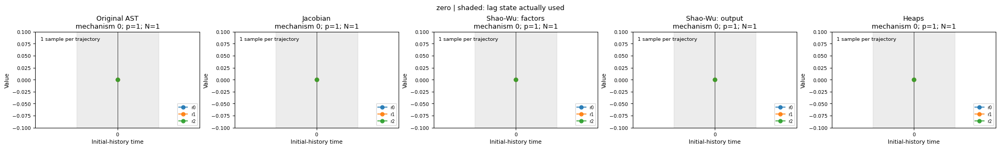

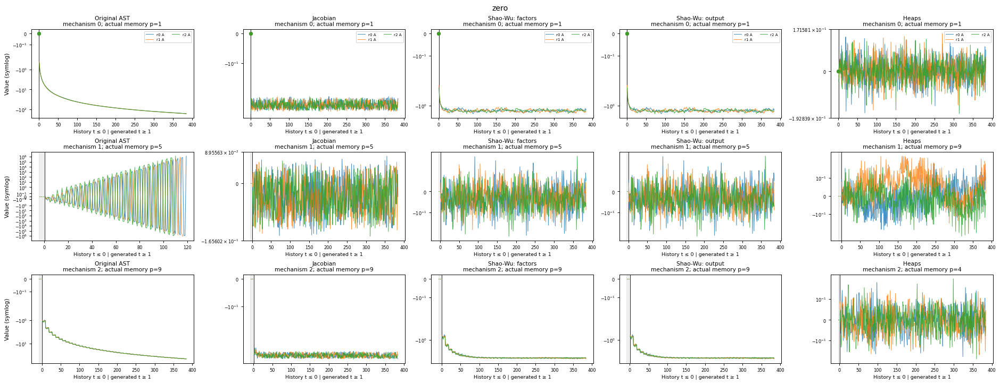

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0055
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0105
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0096
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0105
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0141


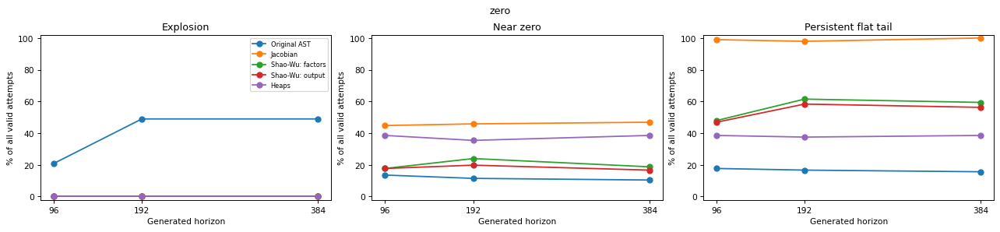

In [2]:
result = show_condition('zero', HistorySpec('zero', 'zero'), CONFIG)

**O que foi feito:** Avaliamos a referência zero uma vez para cada gerador.

## 2. Constante positiva

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

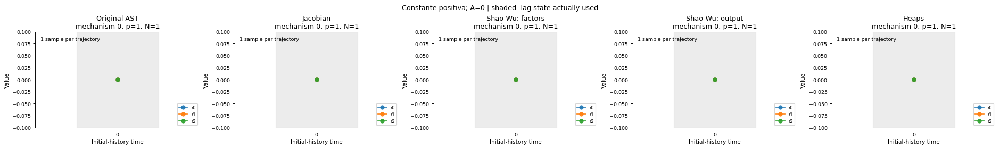

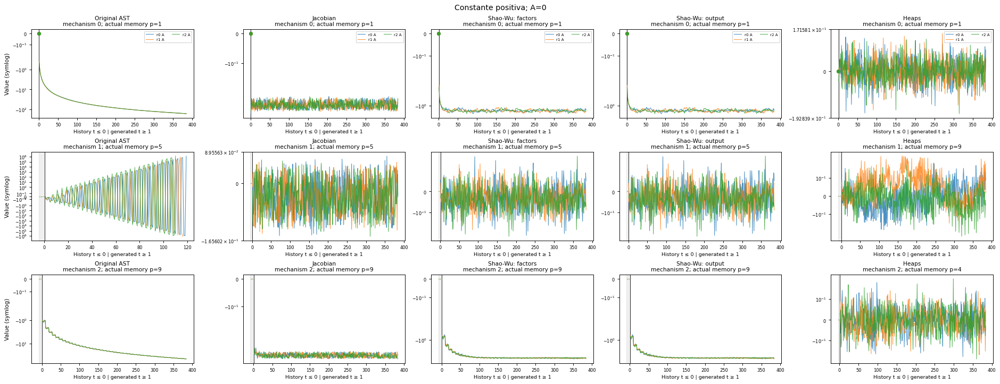

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0073
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0131
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0097
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0100
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0138


In [3]:
scale = 0.0
block = 'Constante positiva; A=0'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

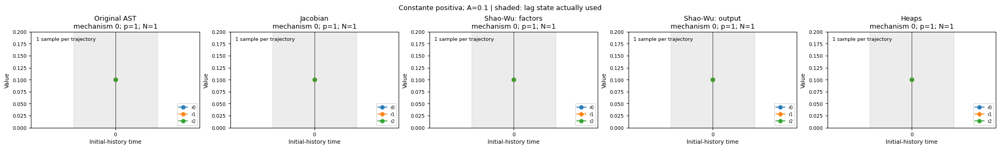

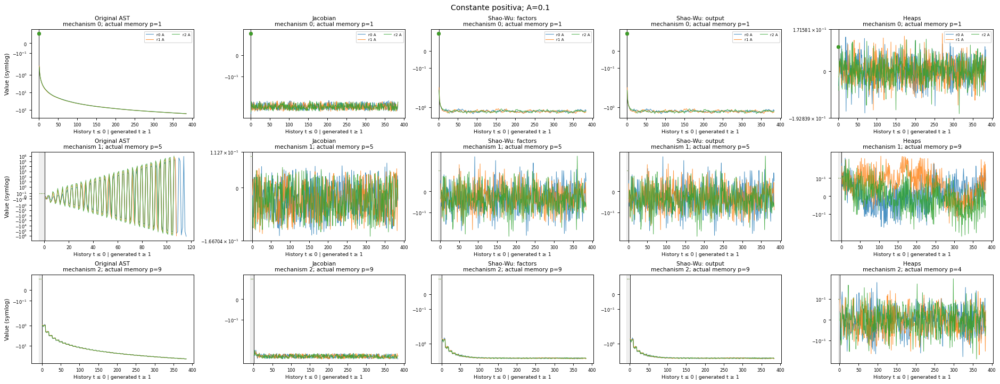

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0064
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0102
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0110
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0115
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0134


In [4]:
scale = 0.1
block = 'Constante positiva; A=0.1'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

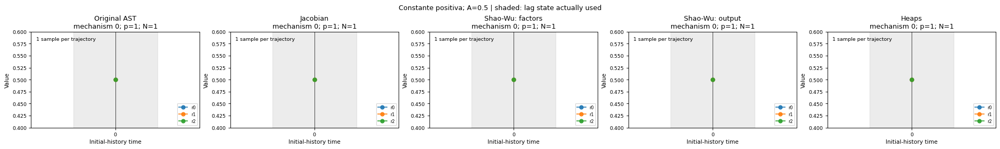

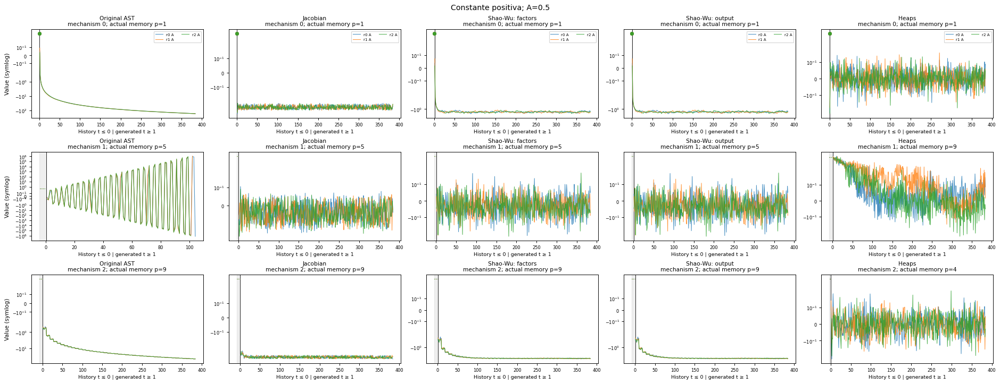

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0054
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0102
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0105
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0097
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0133


In [5]:
scale = 0.5
block = 'Constante positiva; A=0.5'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

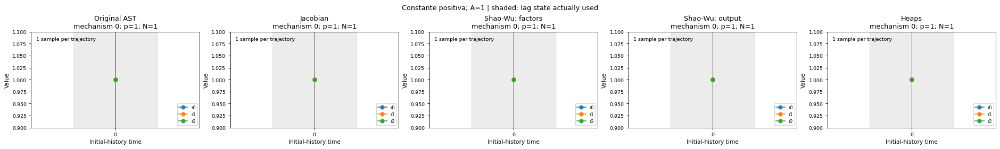

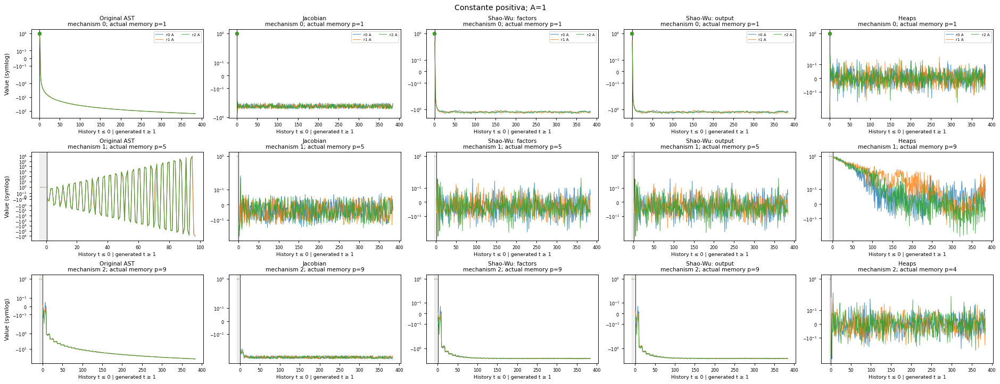

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,52.0833,9.3750,14.5833,0.0000,1,12,0.0056
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0106
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0098
11,Shao-Wu: output,96,0.0000,15.6250,56.2500,32.2917,1,12,0.0118
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0137


In [6]:
scale = 1.0
block = 'Constante positiva; A=1'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


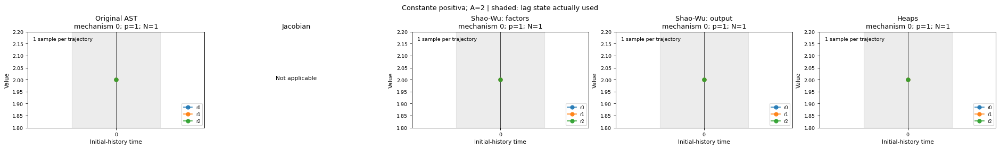

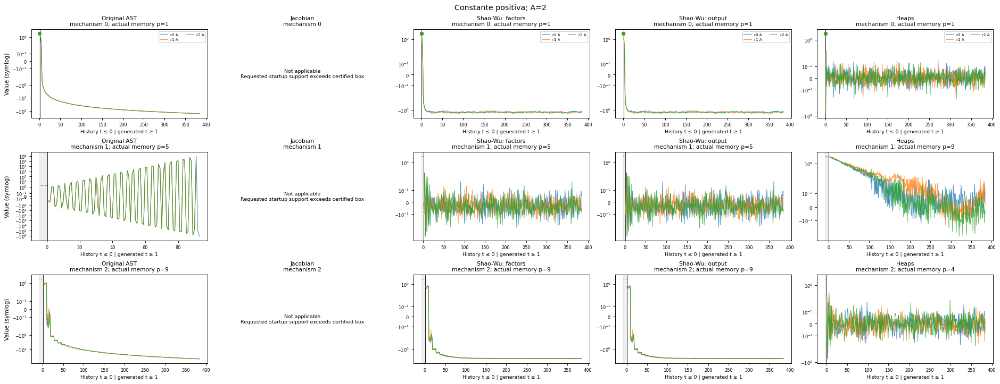

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,52.0833,9.3750,14.5833,0.0000,1,12,0.0055
5,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0118
8,Shao-Wu: output,96,0.0000,15.6250,56.2500,32.2917,1,12,0.0101
11,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0140


In [7]:
scale = 2.0
block = 'Constante positiva; A=2'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


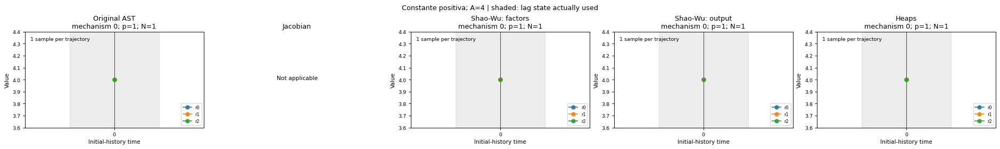

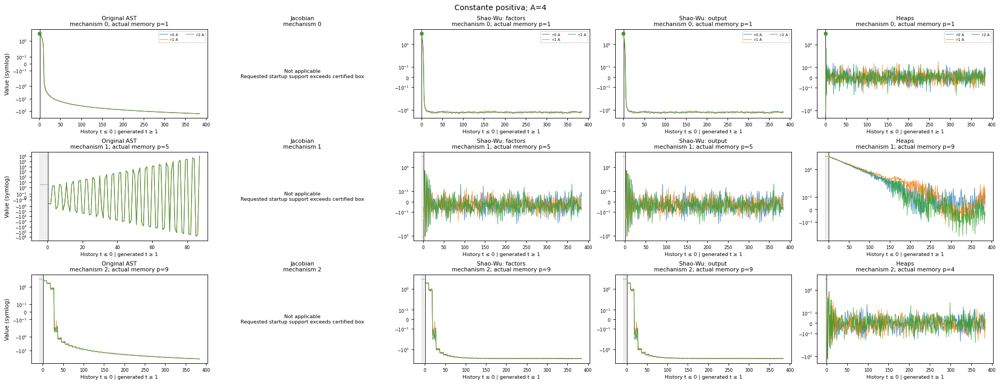

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,52.0833,9.3750,14.5833,0.0000,1,12,0.0053
5,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0099
8,Shao-Wu: output,96,0.0000,15.6250,56.2500,32.2917,1,12,0.0099
11,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0137


In [8]:
scale = 4.0
block = 'Constante positiva; A=4'
result = show_condition(block, HistorySpec(block, 'constant', offset=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

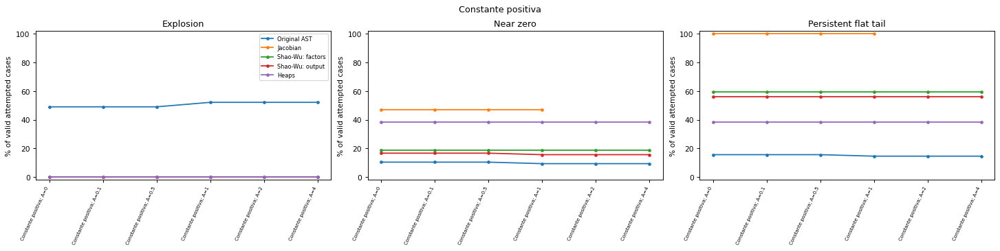

In [9]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Constante positiva')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 3. Constante negativa

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

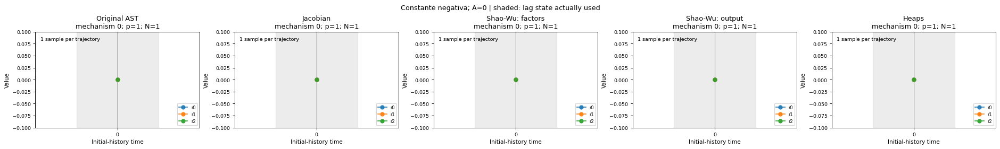

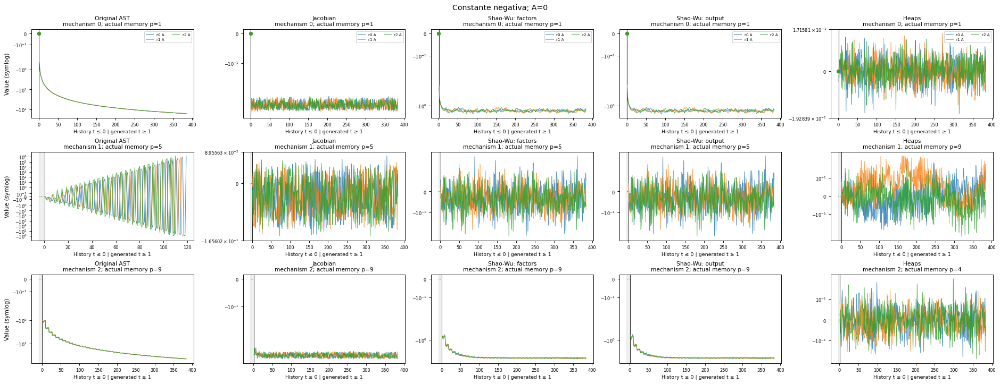

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0058
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0107
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0100
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0103
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0212


In [10]:
scale = 0.0
block = 'Constante negativa; A=0'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

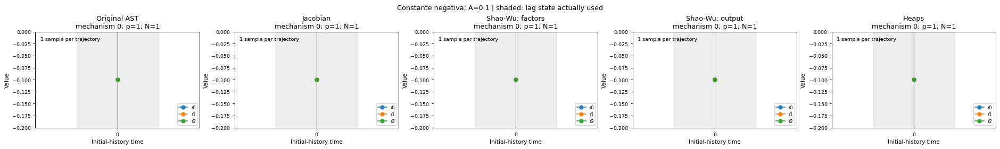

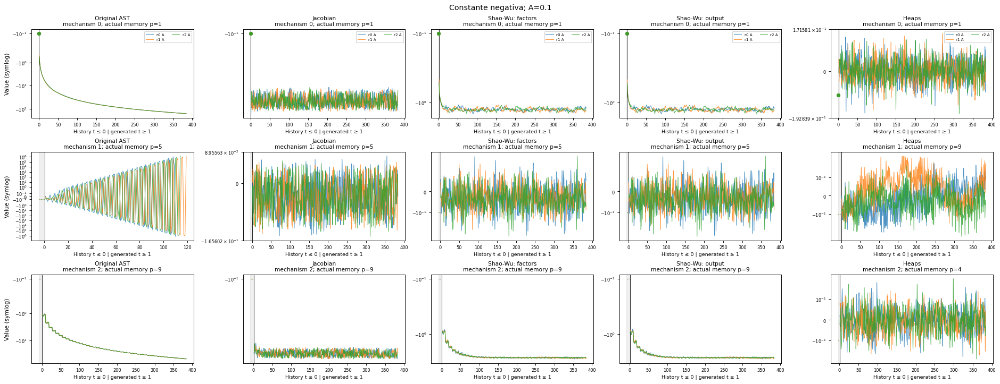

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,50.0,10.4167,15.6250,0.0000,1,12,0.0089
5,Jacobian,96,0.0,46.8750,100.0000,35.4167,1,12,0.0136
8,Shao-Wu: factors,96,0.0,18.7500,59.3750,27.0833,1,12,0.0125
11,Shao-Wu: output,96,0.0,16.6667,56.2500,30.2083,1,12,0.0118
14,Heaps,96,0.0,38.5417,38.5417,0.0000,1,12,0.0171


In [11]:
scale = 0.1
block = 'Constante negativa; A=0.1'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

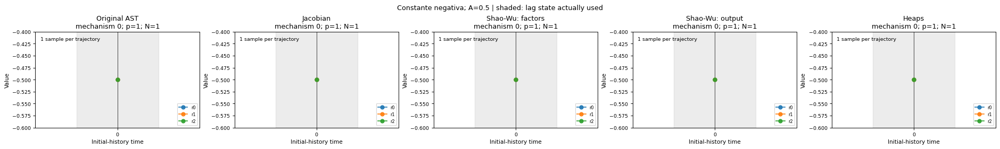

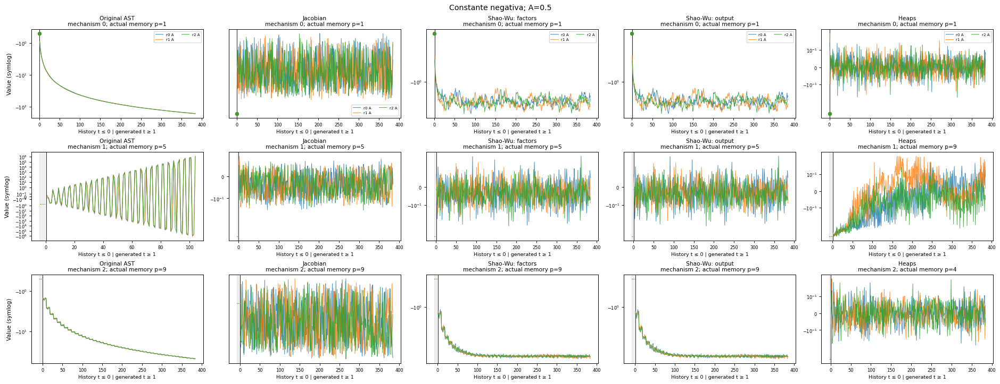

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,50.0,10.4167,15.6250,0.0000,1,12,0.0067
5,Jacobian,96,0.0,46.8750,100.0000,35.4167,1,12,0.0128
8,Shao-Wu: factors,96,0.0,18.7500,59.3750,27.0833,1,12,0.0123
11,Shao-Wu: output,96,0.0,16.6667,56.2500,30.2083,1,12,0.0172
14,Heaps,96,0.0,38.5417,38.5417,0.0000,1,12,0.0238


In [12]:
scale = 0.5
block = 'Constante negativa; A=0.5'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

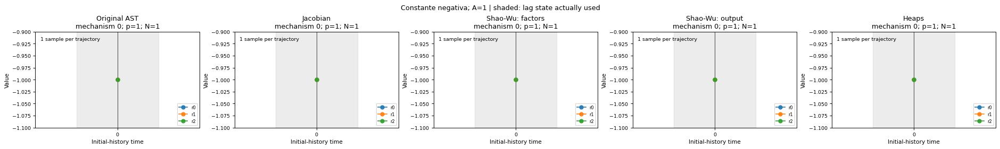

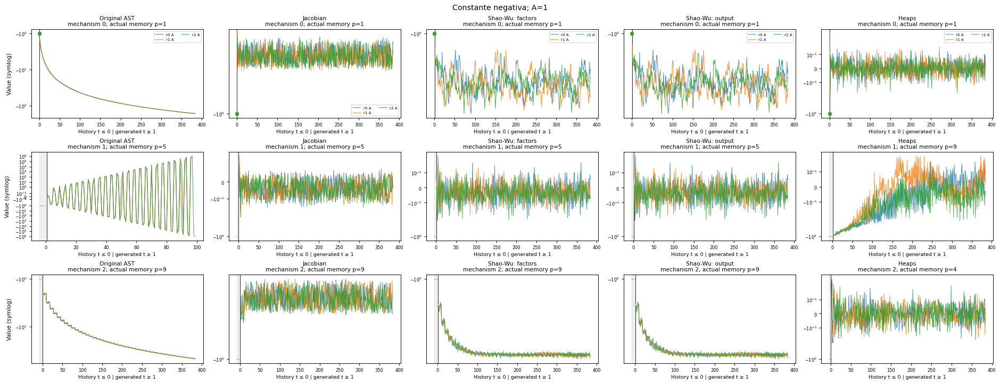

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,53.125,9.3750,14.5833,0.0000,1,12,0.0079
5,Jacobian,96,0.000,46.8750,100.0000,35.4167,1,12,0.0134
8,Shao-Wu: factors,96,0.000,18.7500,59.3750,27.0833,1,12,0.0135
11,Shao-Wu: output,96,0.000,16.6667,56.2500,30.2083,1,12,0.0125
14,Heaps,96,0.000,38.5417,37.5000,0.0000,1,12,0.0157


In [13]:
scale = 1.0
block = 'Constante negativa; A=1'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


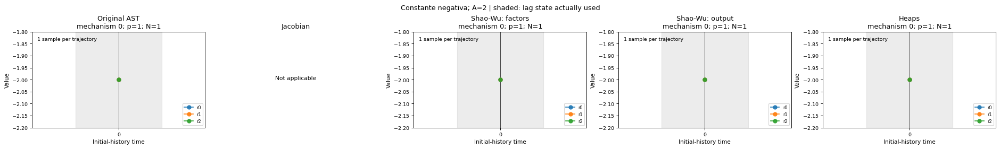

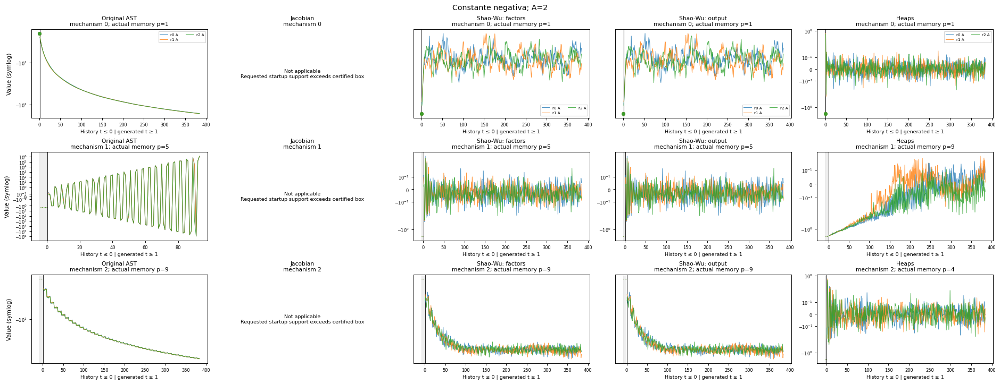

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,53.125,9.3750,14.5833,0.0000,1,12,0.0055
5,Shao-Wu: factors,96,0.000,18.7500,59.3750,27.0833,1,12,0.0113
8,Shao-Wu: output,96,0.000,16.6667,56.2500,30.2083,1,12,0.0105
11,Heaps,96,0.000,38.5417,37.5000,0.0000,1,12,0.0138


In [14]:
scale = 2.0
block = 'Constante negativa; A=2'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


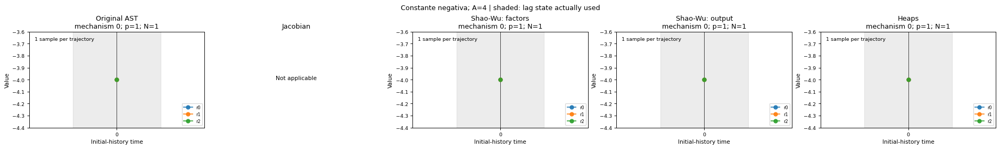

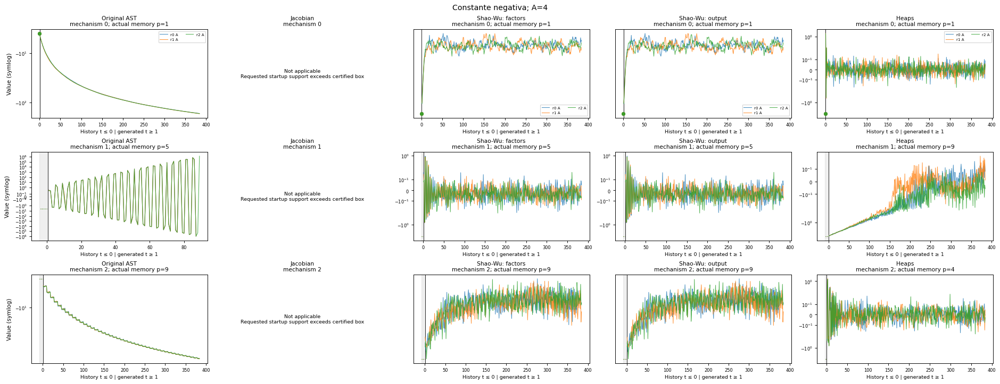

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,53.125,9.3750,14.5833,0.0000,1,12,0.0051
5,Shao-Wu: factors,96,0.000,18.7500,59.3750,27.0833,1,12,0.0099
8,Shao-Wu: output,96,0.000,16.6667,56.2500,30.2083,1,12,0.0137
11,Heaps,96,0.000,38.5417,37.5000,0.0000,1,12,0.0162


In [15]:
scale = 4.0
block = 'Constante negativa; A=4'
result = show_condition(block, HistorySpec(block, 'constant', offset=-scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

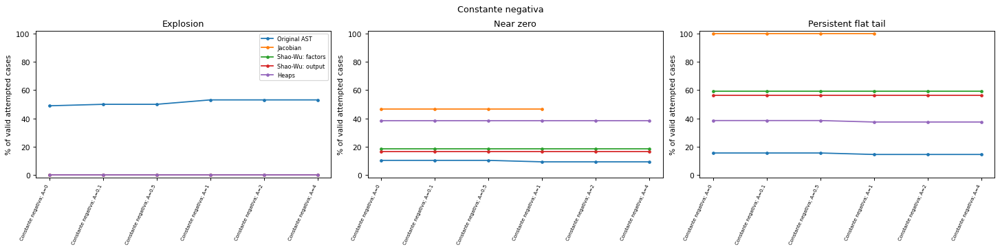

In [16]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Constante negativa')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 4. Uniforme aleatório

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

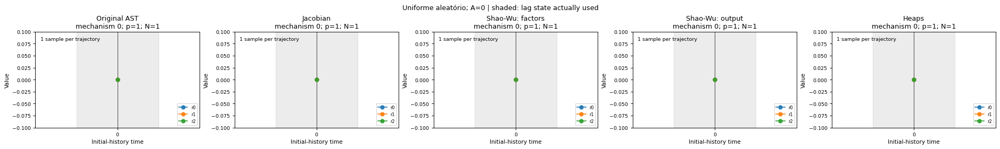

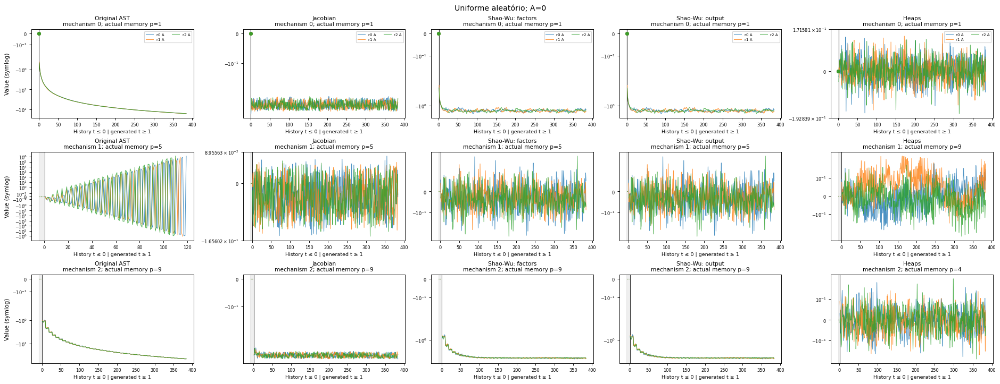

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0058
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0124
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0104
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0105
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0160


In [17]:
scale = 0.0
block = 'Uniforme aleatório; A=0'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

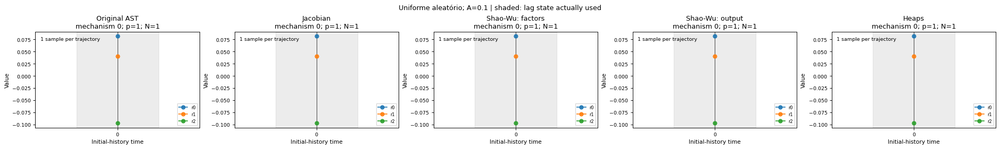

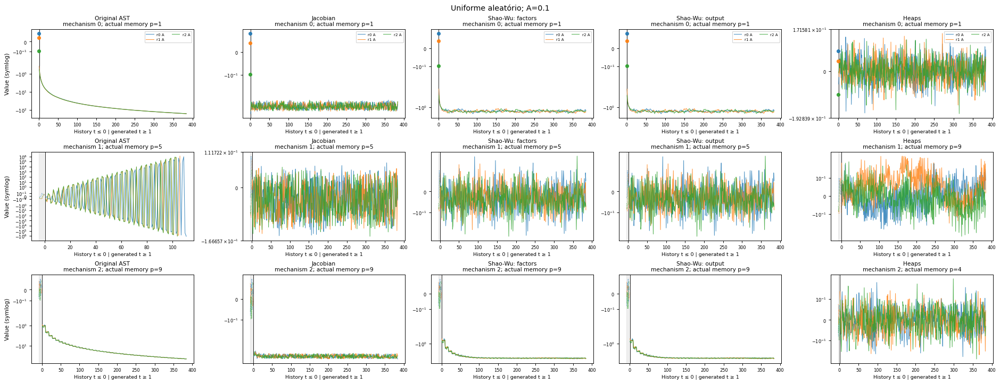

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0069
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0120
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0101
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0098
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0164


In [18]:
scale = 0.1
block = 'Uniforme aleatório; A=0.1'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

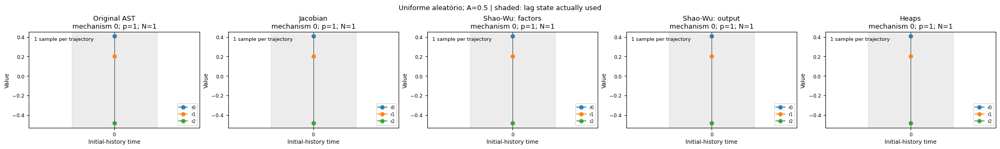

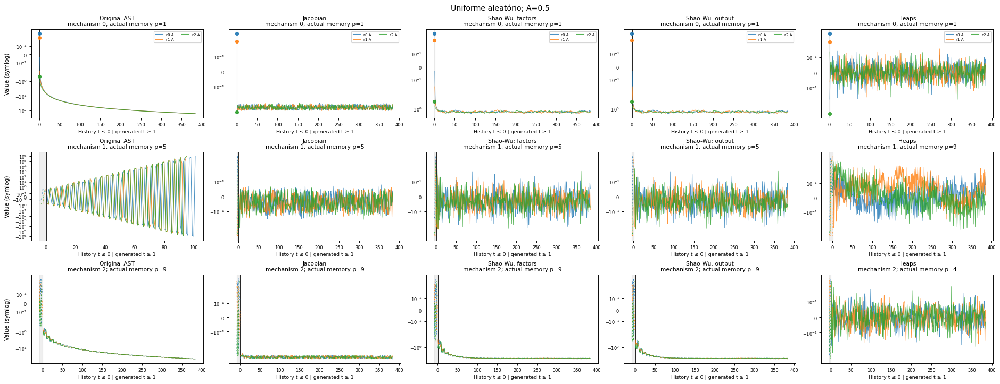

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0064
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0131
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0104
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0104
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0154


In [19]:
scale = 0.5
block = 'Uniforme aleatório; A=0.5'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

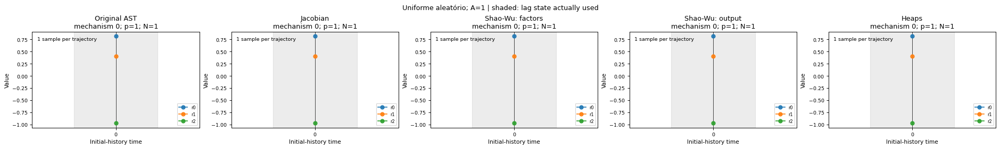

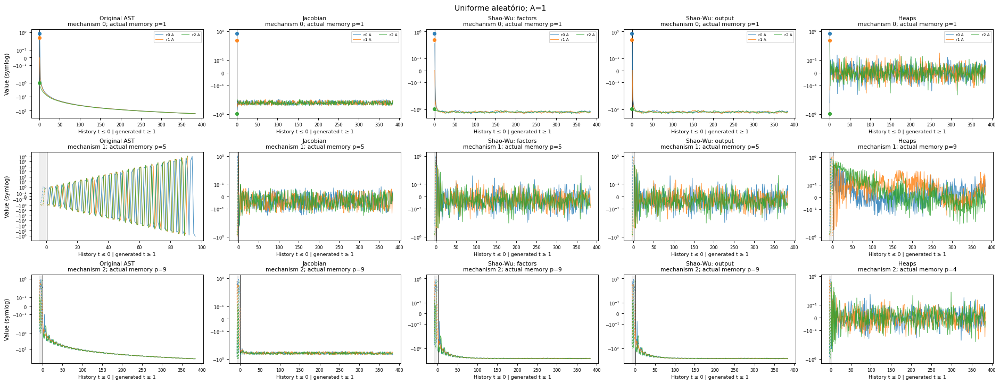

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0055
5,Jacobian,96,0.0000,46.8750,100.0000,35.4167,1,12,0.0110
8,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0102
11,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0105
14,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0159


In [20]:
scale = 1.0
block = 'Uniforme aleatório; A=1'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


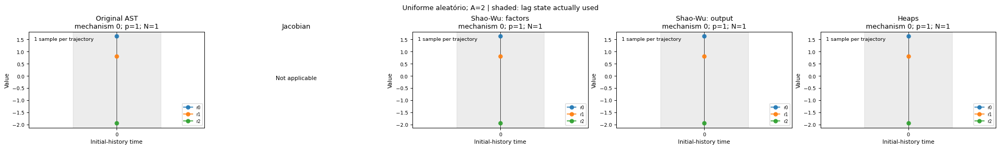

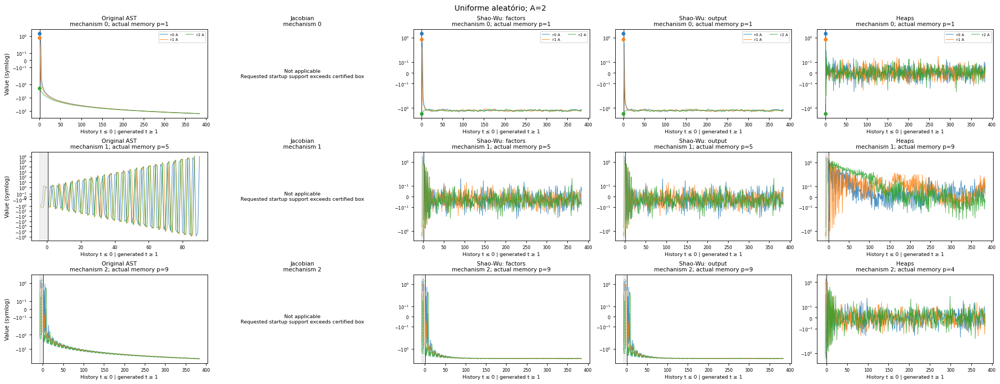

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,48.9583,10.4167,15.6250,0.0000,1,12,0.0069
5,Shao-Wu: factors,96,0.0000,18.7500,59.3750,27.0833,1,12,0.0134
8,Shao-Wu: output,96,0.0000,16.6667,56.2500,30.2083,1,12,0.0129
11,Heaps,96,0.0000,38.5417,38.5417,0.0000,1,12,0.0156


In [21]:
scale = 2.0
block = 'Uniforme aleatório; A=2'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,96


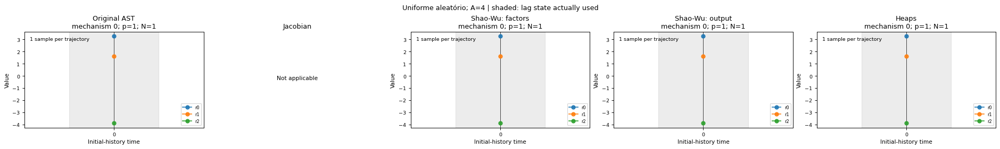

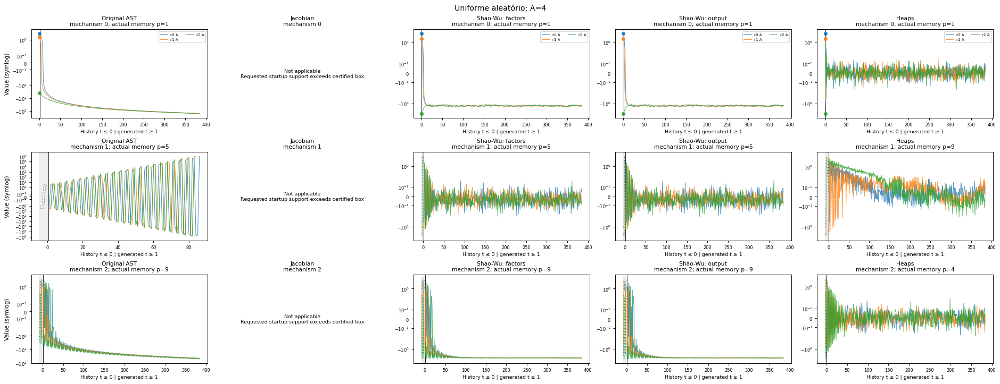

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,96,50.0,10.4167,15.6250,0.0000,1,12,0.0096
5,Shao-Wu: factors,96,0.0,18.7500,59.3750,27.0833,1,12,0.0115
8,Shao-Wu: output,96,0.0,16.6667,56.2500,30.2083,1,12,0.0111
11,Heaps,96,0.0,38.5417,38.5417,0.0000,1,12,0.0170


In [22]:
scale = 4.0
block = 'Uniforme aleatório; A=4'
result = show_condition(block, HistorySpec(block, 'uniform', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

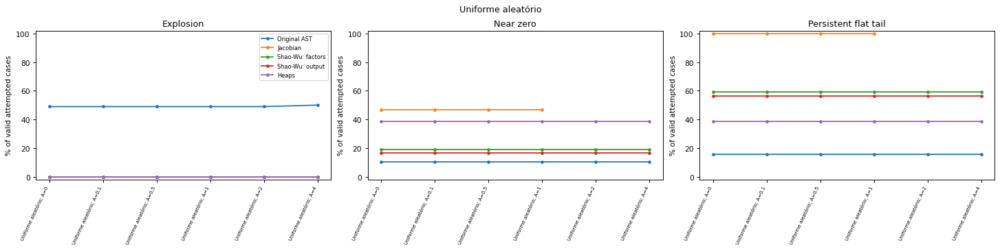

In [23]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Uniforme aleatório')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 5. Histórico estacionário com escala

A escala 1 preserva a distribuição estacionária de Heaps; as demais escalas transformam esse histórico e avaliam o transiente resultante. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


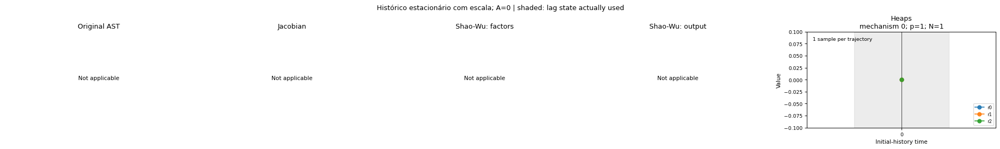

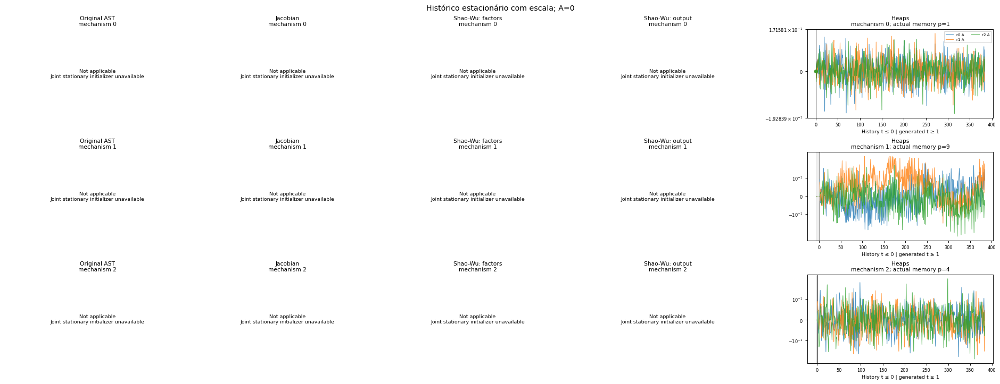

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0157


In [24]:
scale = 0.0
block = 'Histórico estacionário com escala; A=0'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


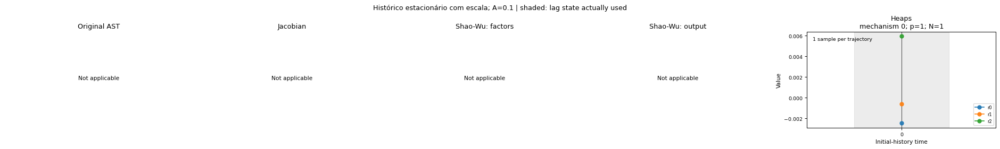

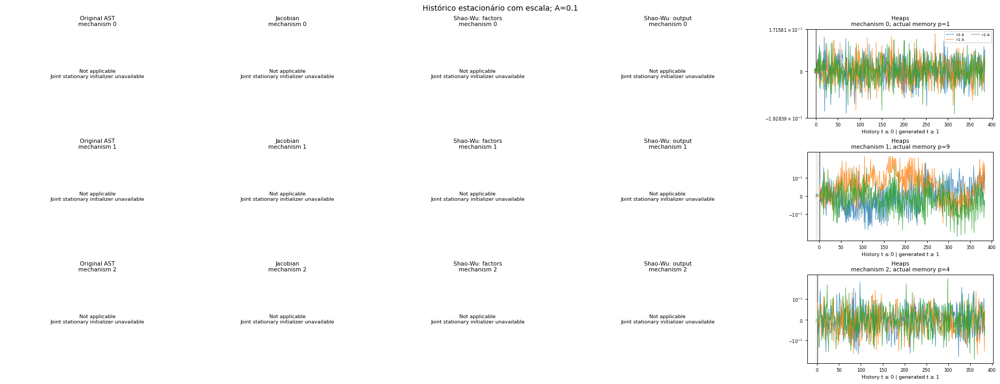

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0155


In [25]:
scale = 0.1
block = 'Histórico estacionário com escala; A=0.1'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


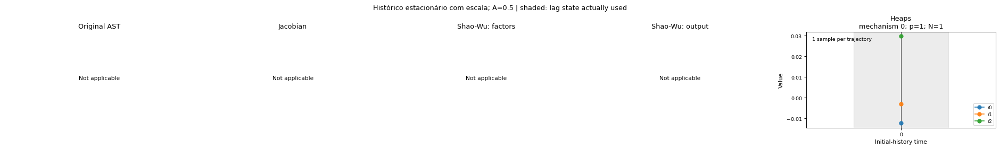

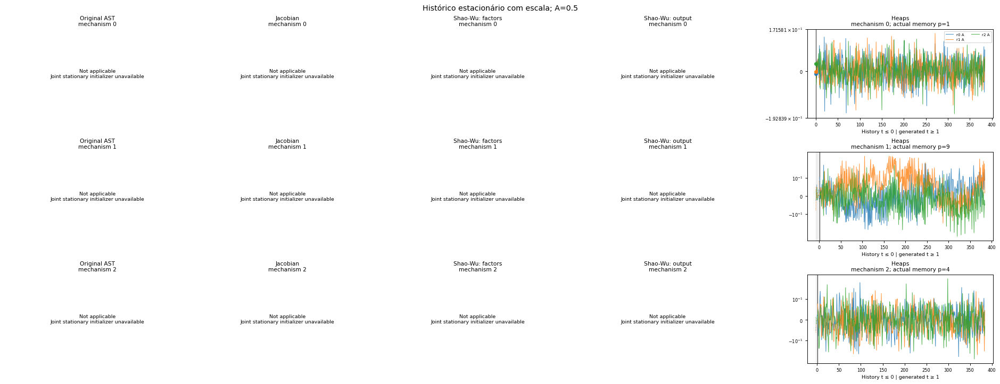

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0162


In [26]:
scale = 0.5
block = 'Histórico estacionário com escala; A=0.5'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


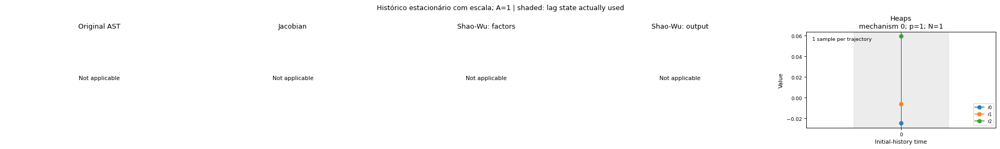

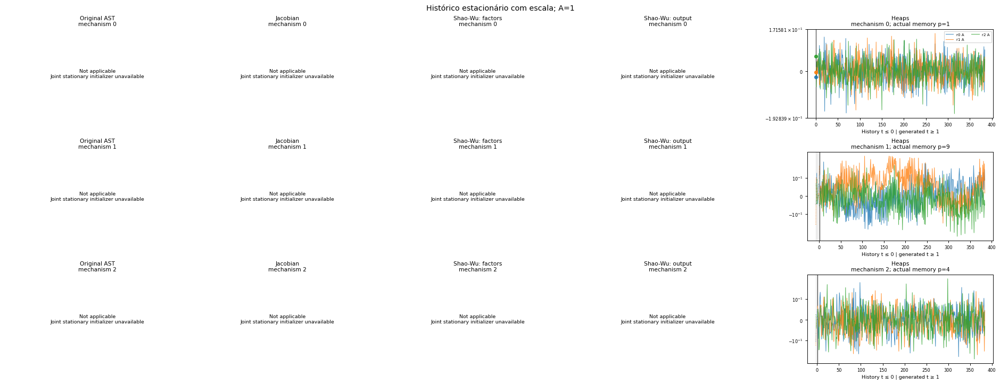

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0155


In [27]:
scale = 1.0
block = 'Histórico estacionário com escala; A=1'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


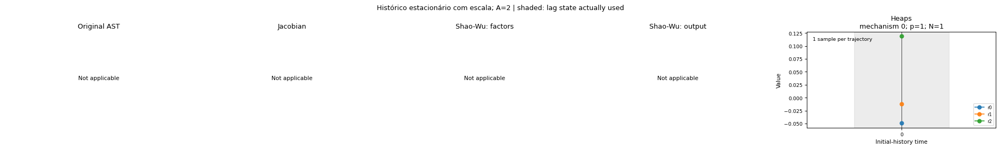

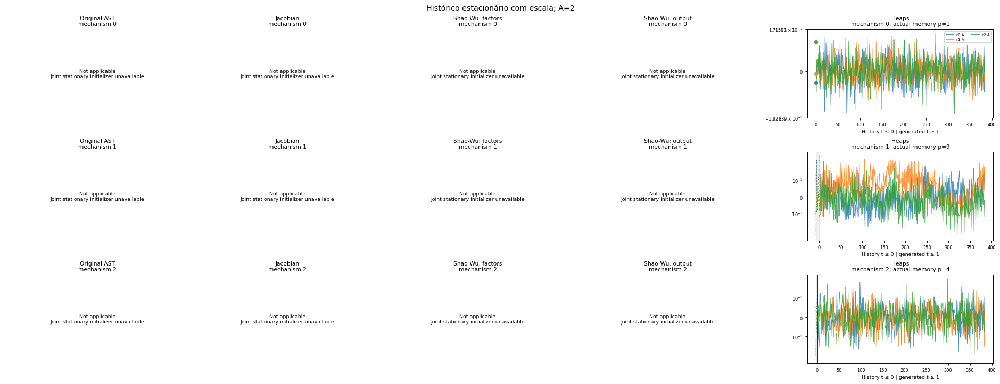

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0163


In [28]:
scale = 2.0
block = 'Histórico estacionário com escala; A=2'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


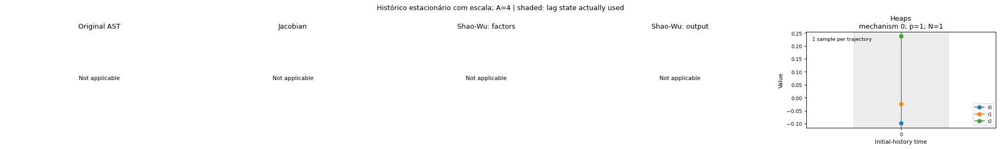

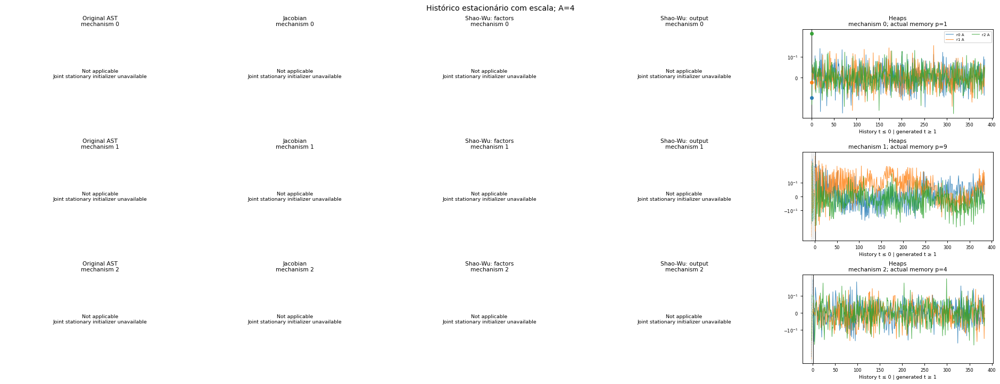

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Heaps,96,0.0,38.5417,38.5417,0.0,1,12,0.0159


In [29]:
scale = 4.0
block = 'Histórico estacionário com escala; A=4'
result = show_condition(block, HistorySpec(block, 'stationary', amplitude=scale), CONFIG, overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

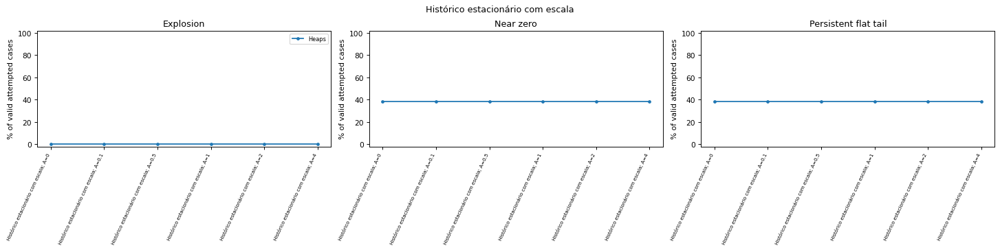

In [30]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Histórico estacionário com escala')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 6. Cosseno completo

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

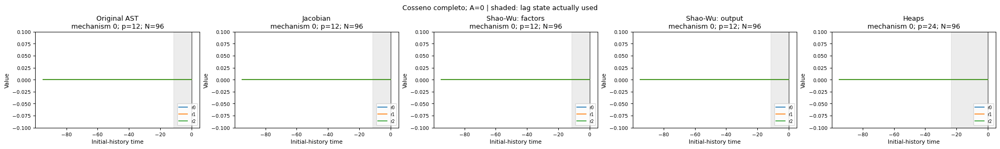

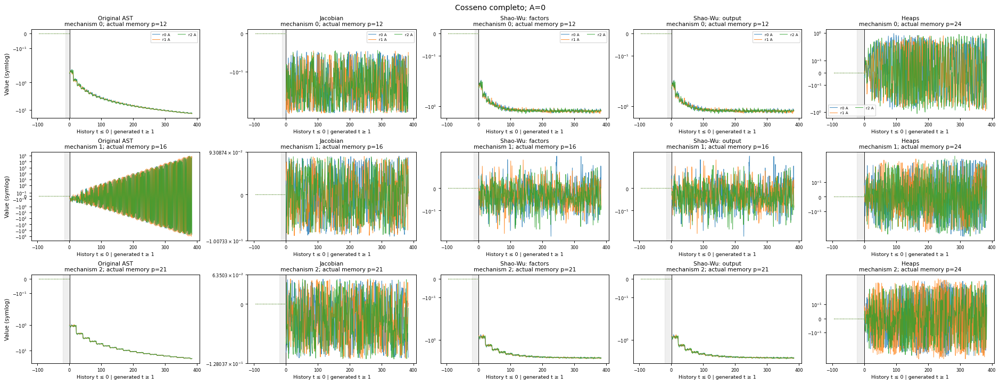

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0103
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0122
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0118
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0112
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0366


In [31]:
scale = 0.0
block = 'Cosseno completo; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

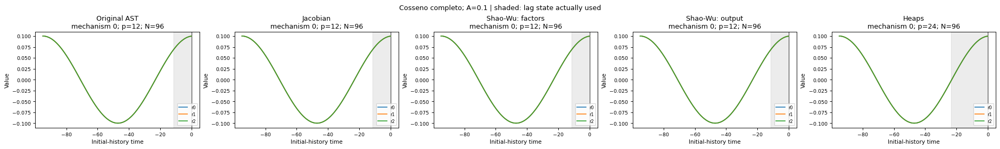

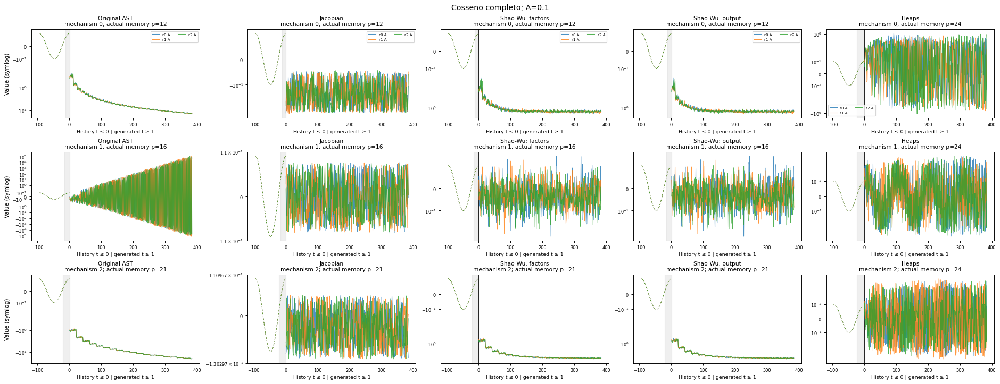

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0093
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0131
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0114
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0119
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0334


In [32]:
scale = 0.1
block = 'Cosseno completo; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

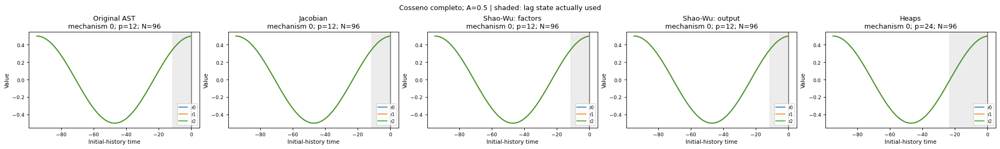

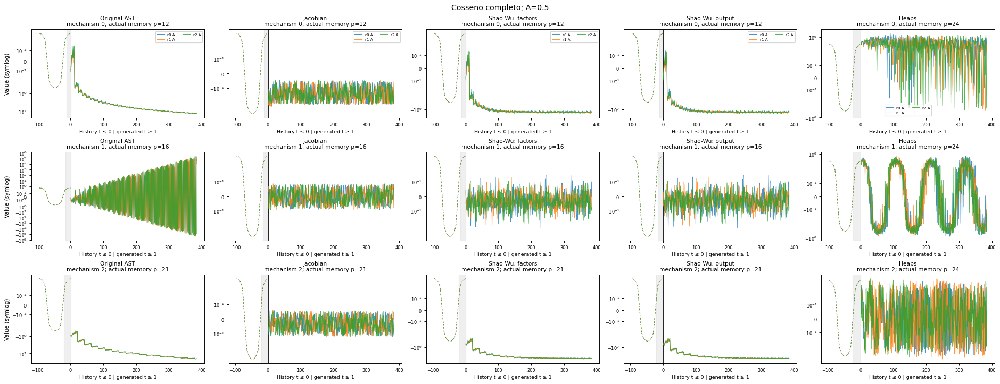

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0097
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0166
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0135
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0113
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0343


In [33]:
scale = 0.5
block = 'Cosseno completo; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

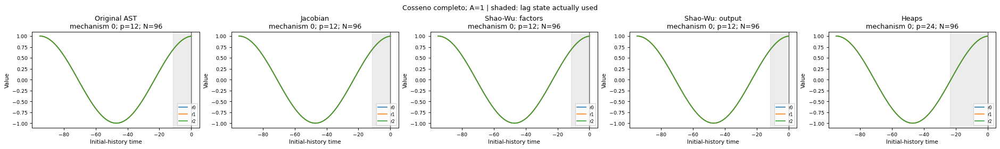

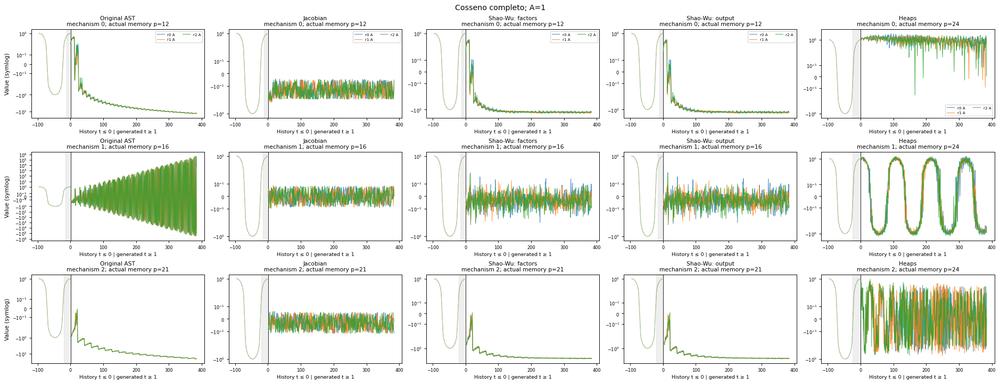

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0089
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0123
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0114
11,Shao-Wu: output,36,0.0000,8.3333,36.1111,13.8889,12,24,0.0128
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0331


In [34]:
scale = 1.0
block = 'Cosseno completo; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


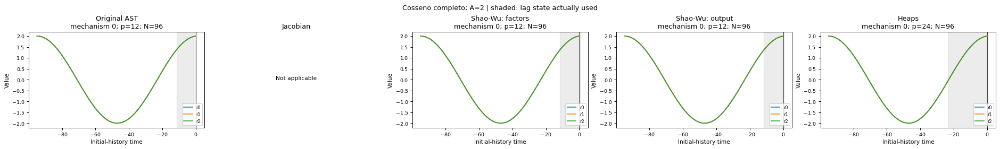

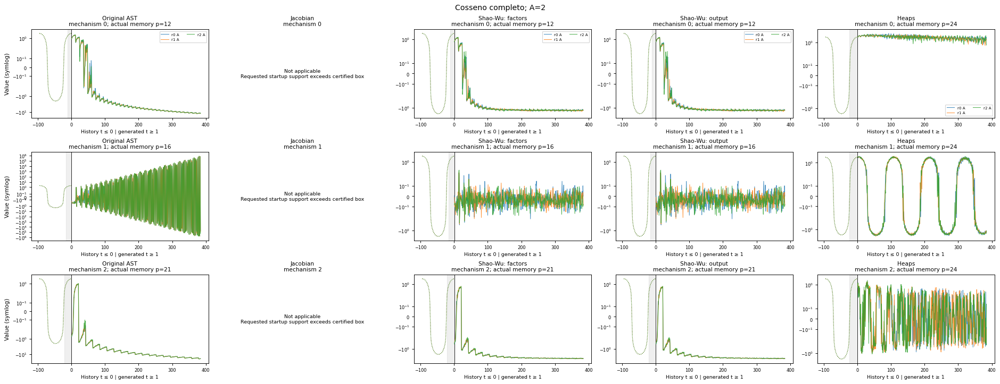

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0091
5,Shao-Wu: factors,36,0.0000,13.8889,44.4444,16.6667,12,24,0.0113
8,Shao-Wu: output,36,0.0000,8.3333,44.4444,22.2222,12,24,0.0111
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0455


In [35]:
scale = 2.0
block = 'Cosseno completo; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


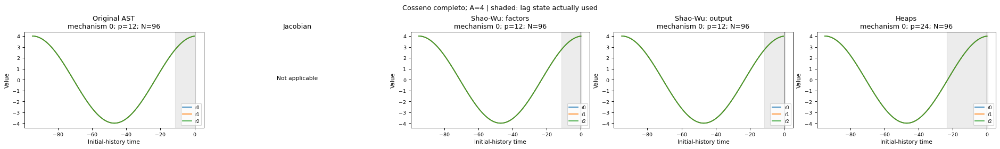

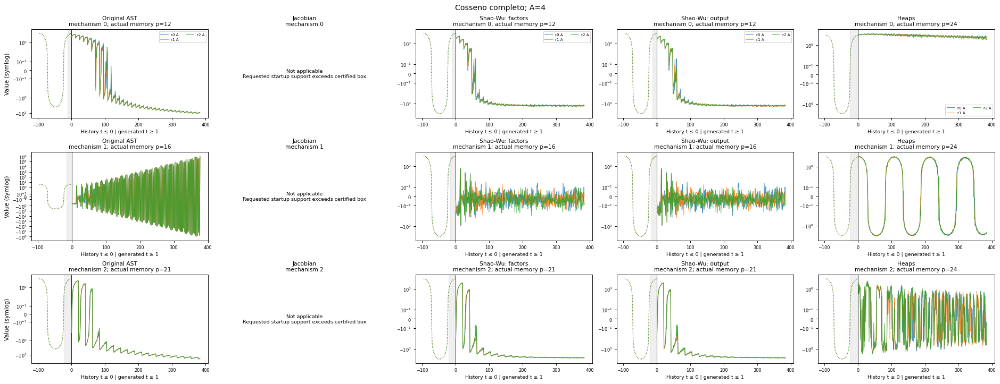

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,5.5556,8.3333,0.0000,12,24,0.0076
5,Shao-Wu: factors,36,0.0000,13.8889,44.4444,16.6667,12,24,0.0099
8,Shao-Wu: output,36,0.0000,8.3333,44.4444,22.2222,12,24,0.0100
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0309


In [36]:
scale = 4.0
block = 'Cosseno completo; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

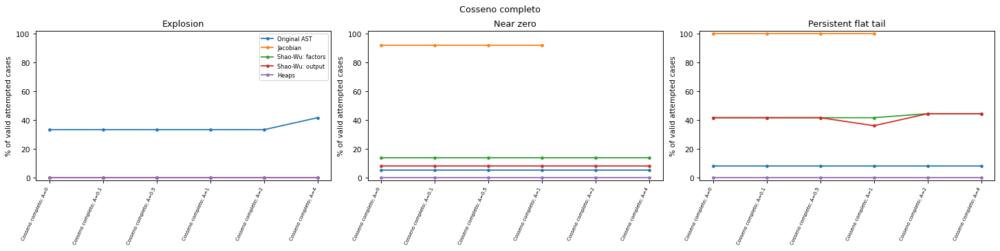

In [37]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno completo')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 7. Cosseno metade

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

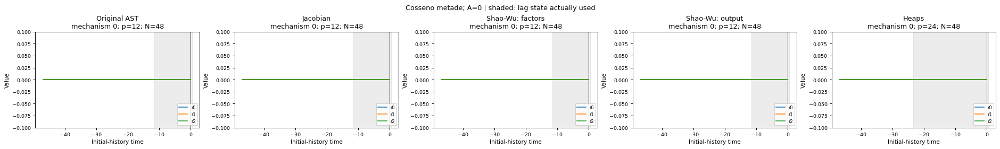

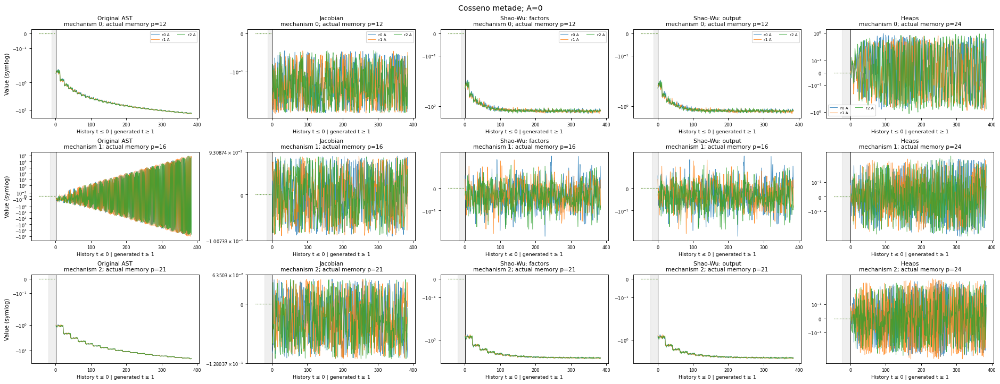

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0085
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0107
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0095
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0098
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0287


In [38]:
scale = 0.0
block = 'Cosseno metade; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

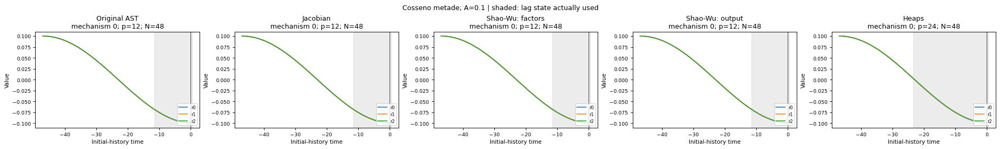

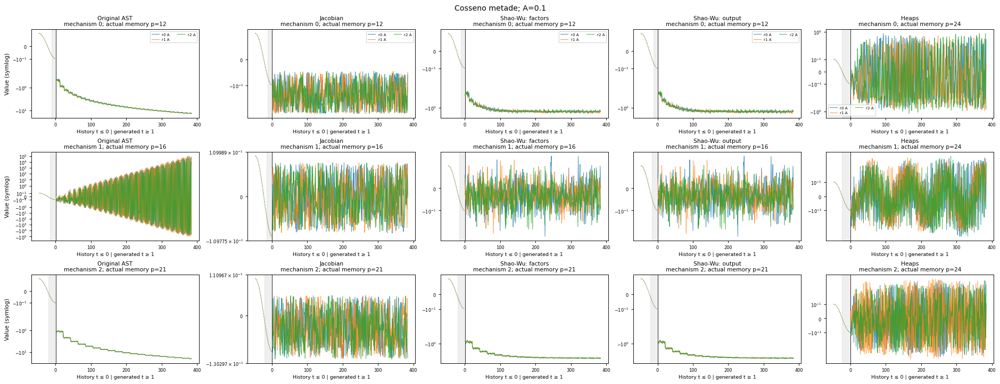

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0079
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0108
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0100
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0114
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0683


In [39]:
scale = 0.1
block = 'Cosseno metade; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

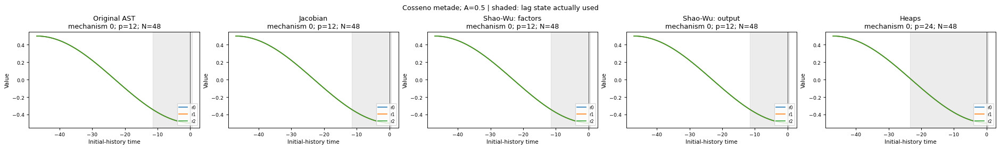

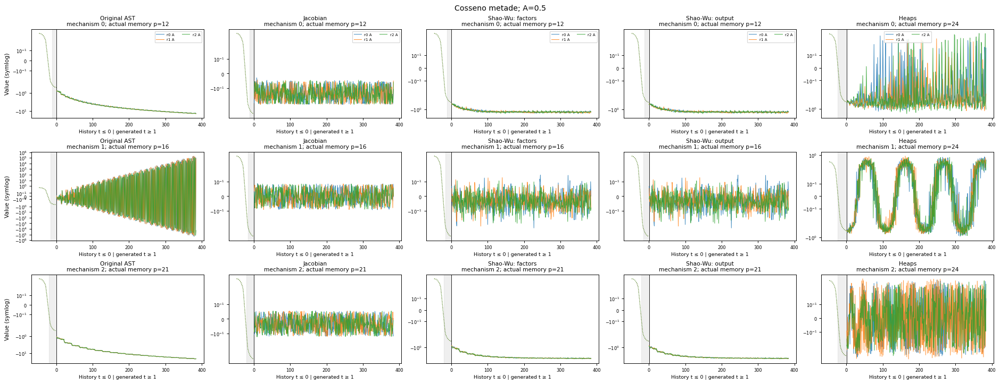

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0092
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0107
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0106
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0104
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0291


In [40]:
scale = 0.5
block = 'Cosseno metade; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

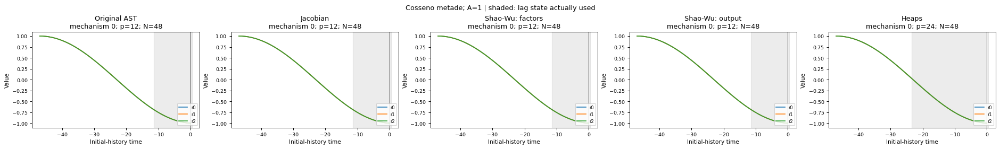

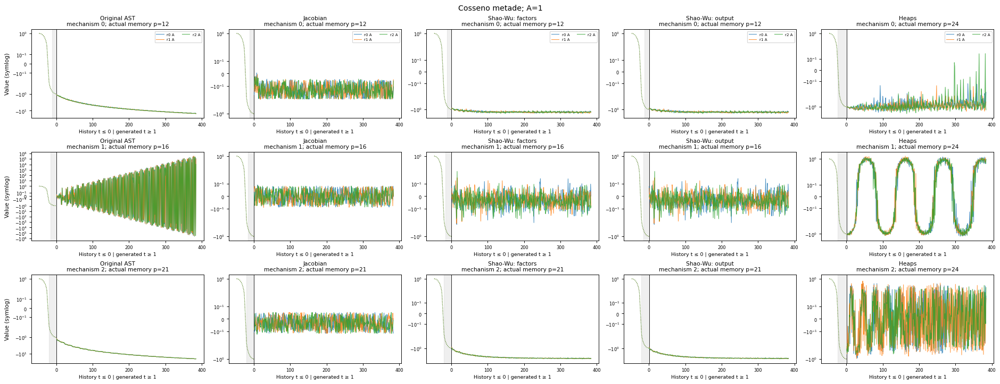

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0077
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0123
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0103
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0127
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0317


In [41]:
scale = 1.0
block = 'Cosseno metade; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


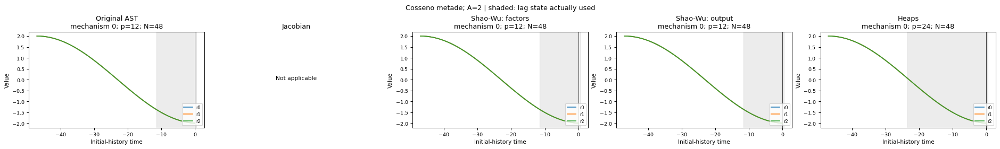

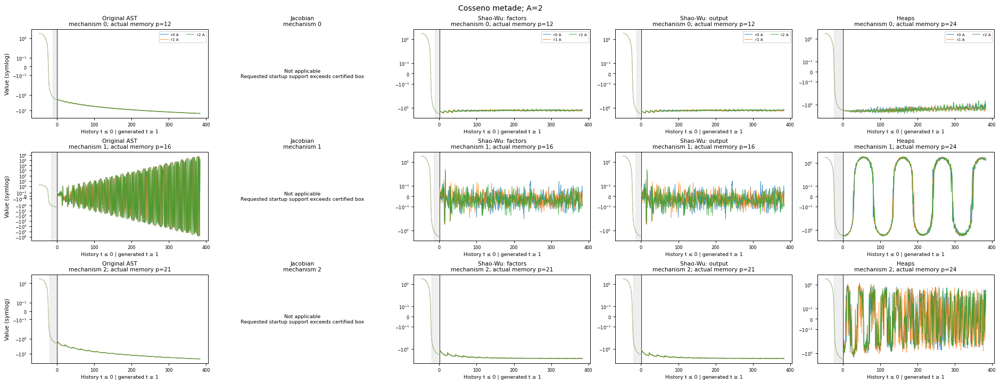

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0079
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0124
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0147
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0310


In [42]:
scale = 2.0
block = 'Cosseno metade; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


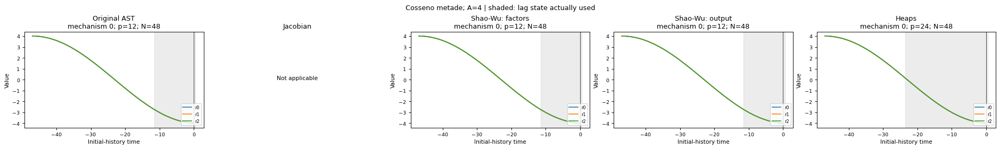

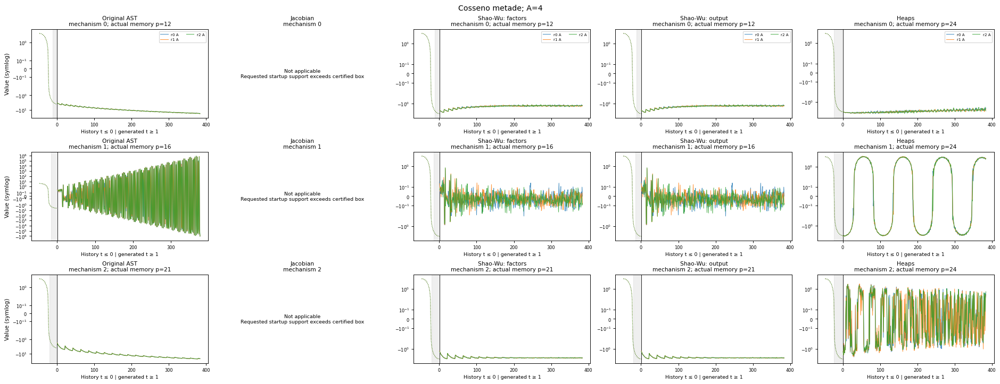

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,5.5556,8.3333,0.0000,12,24,0.0076
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0102
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0103
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0293


In [43]:
scale = 4.0
block = 'Cosseno metade; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

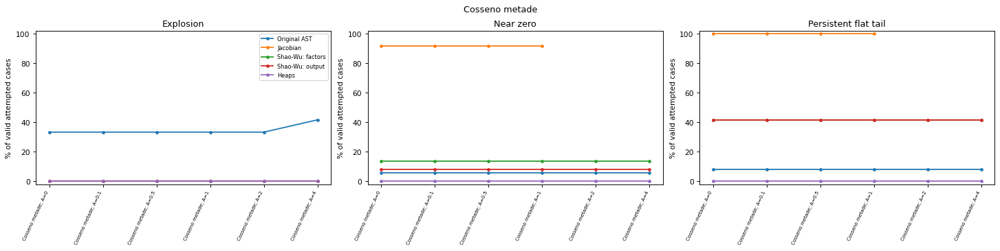

In [44]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno metade')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 8. Cosseno quarto

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

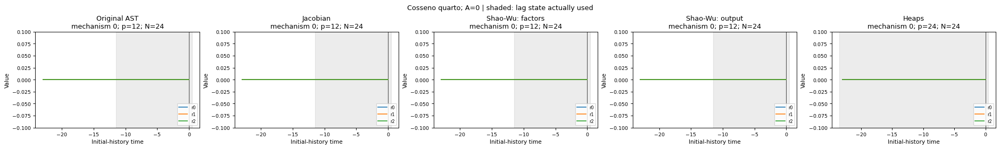

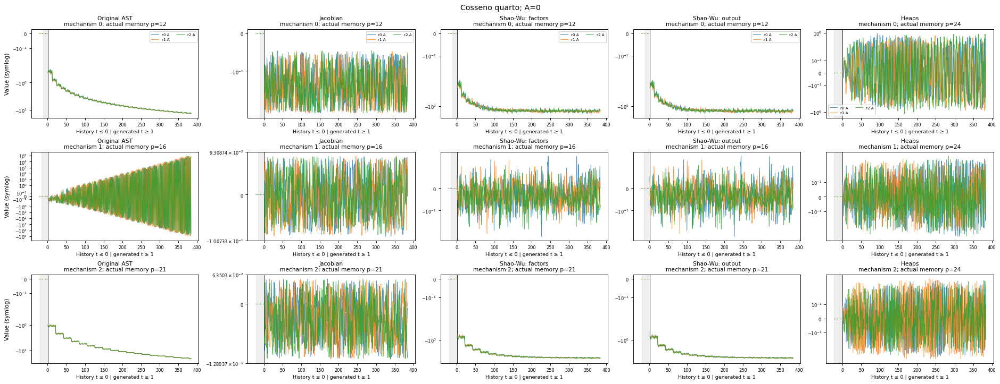

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0083
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0111
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0103
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0099
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0298


In [45]:
scale = 0.0
block = 'Cosseno quarto; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

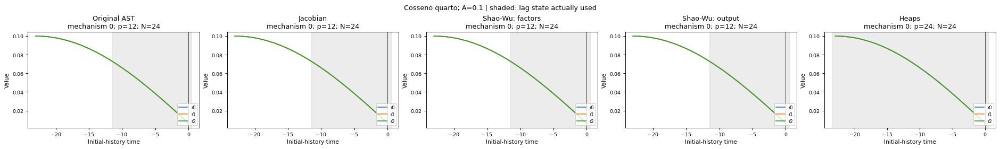

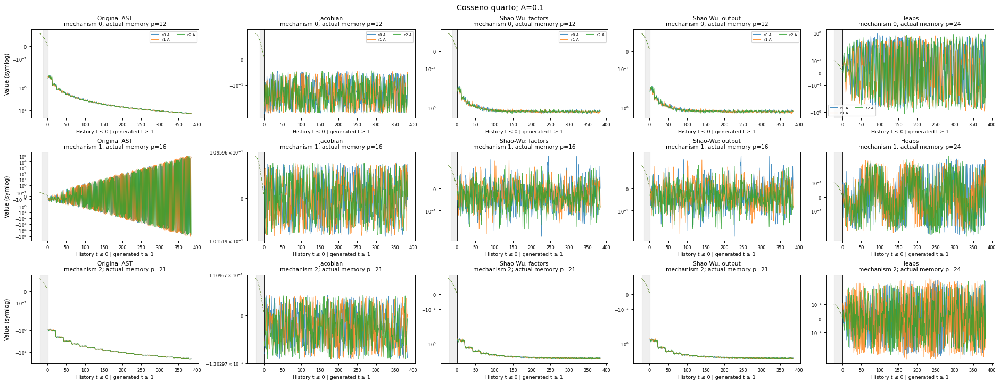

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0082
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0109
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0134
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0116
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0369


In [46]:
scale = 0.1
block = 'Cosseno quarto; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

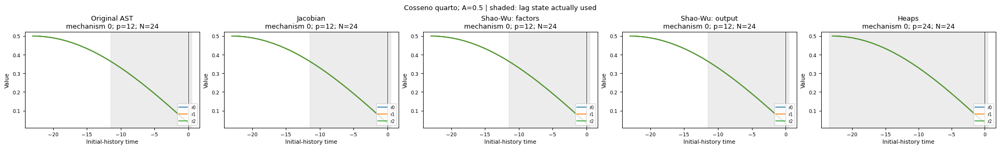

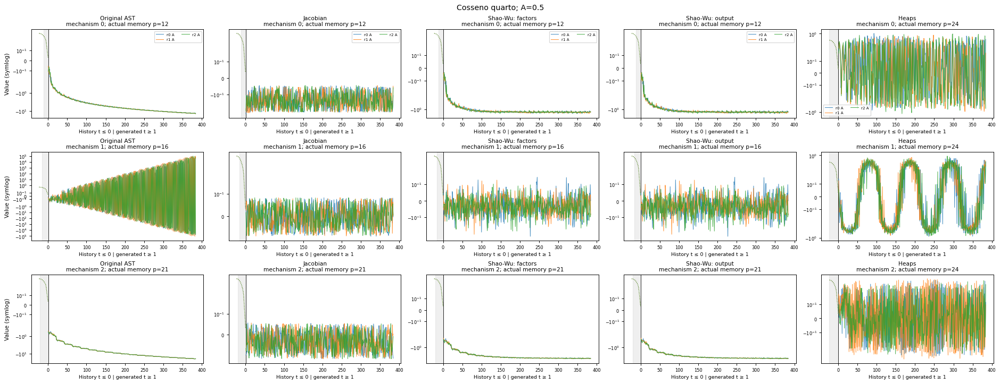

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0105
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0135
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0135
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0136
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0433


In [47]:
scale = 0.5
block = 'Cosseno quarto; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

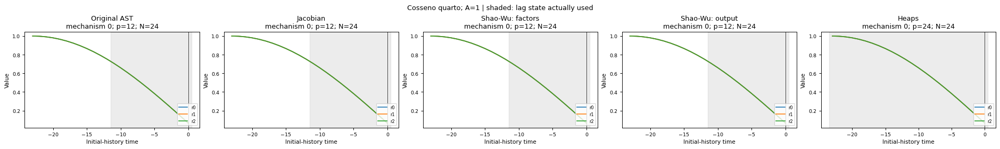

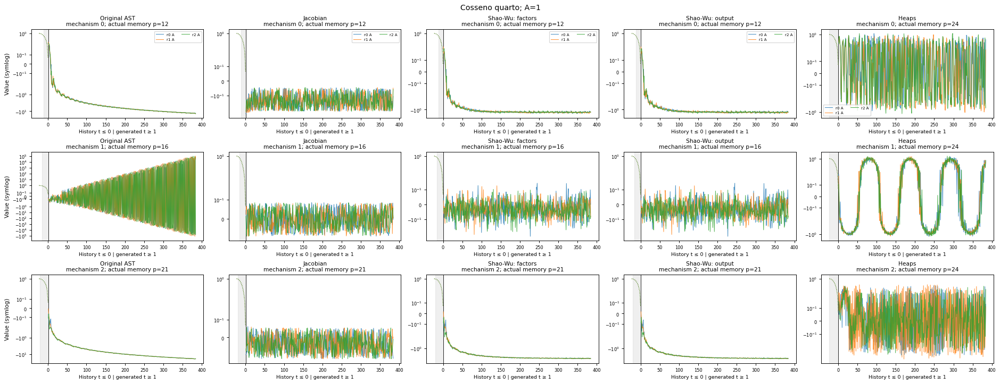

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0098
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0125
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0120
11,Shao-Wu: output,36,0.0000,11.1111,38.8889,13.8889,12,24,0.0116
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0332


In [48]:
scale = 1.0
block = 'Cosseno quarto; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


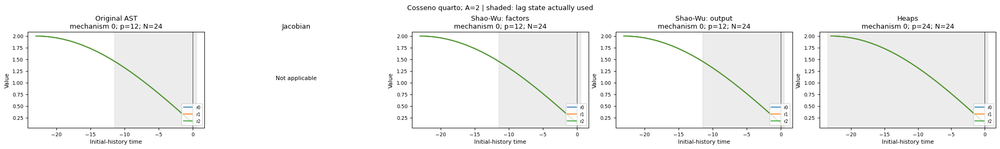

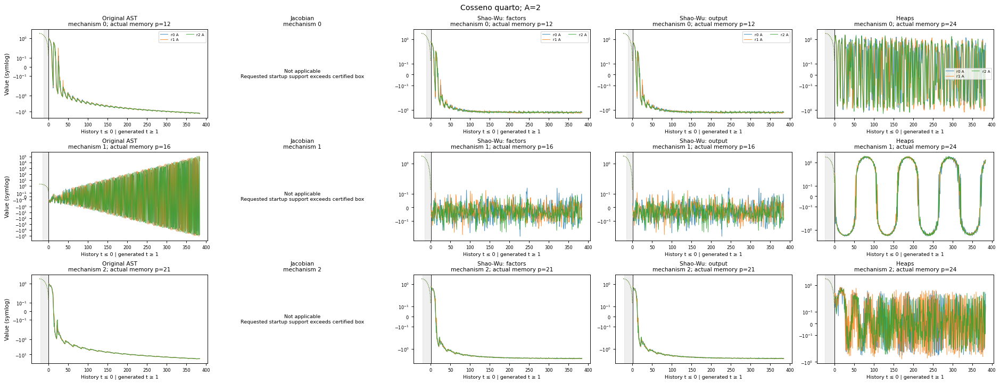

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0087
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0120
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0120
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0329


In [49]:
scale = 2.0
block = 'Cosseno quarto; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


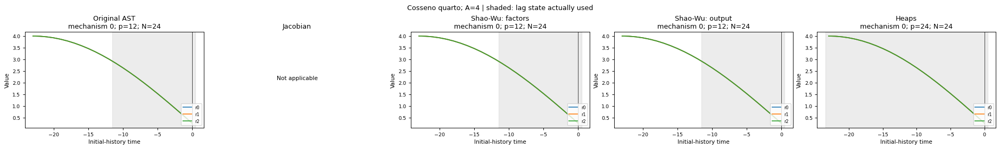

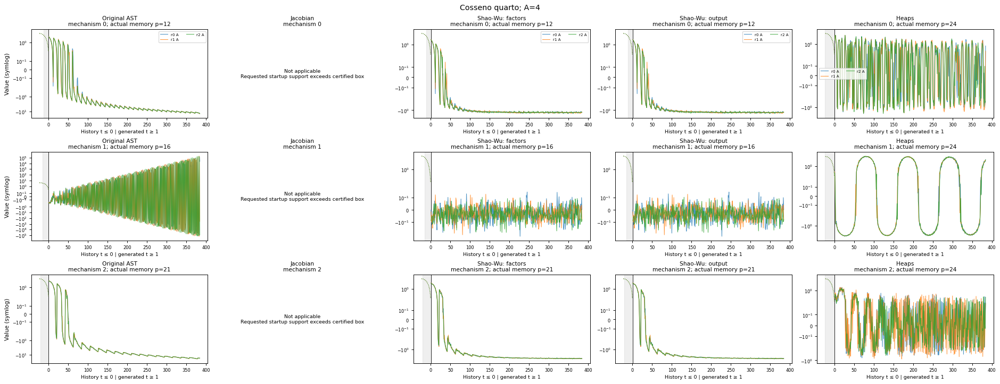

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0069
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0082
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0091
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0265


In [50]:
scale = 4.0
block = 'Cosseno quarto; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.0, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

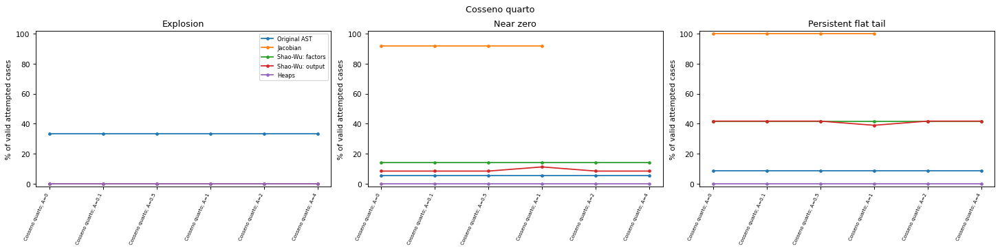

In [51]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno quarto')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 9. Cosseno completo + escalar 0,5

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

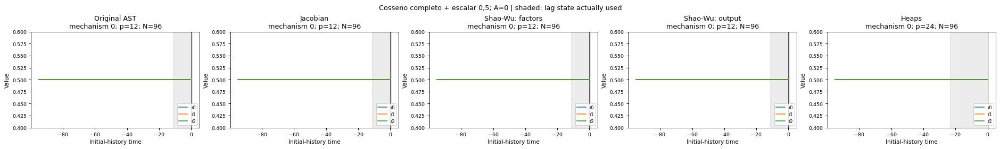

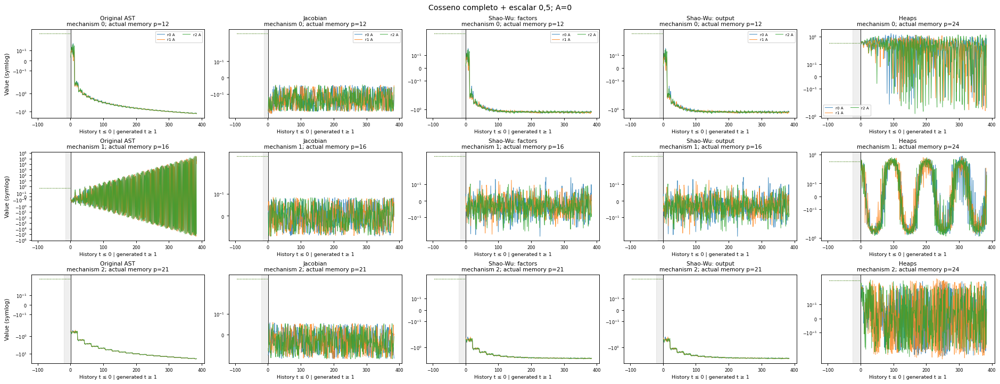

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0098
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0095
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0110
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0091
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0271


In [52]:
scale = 0.0
block = 'Cosseno completo + escalar 0,5; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

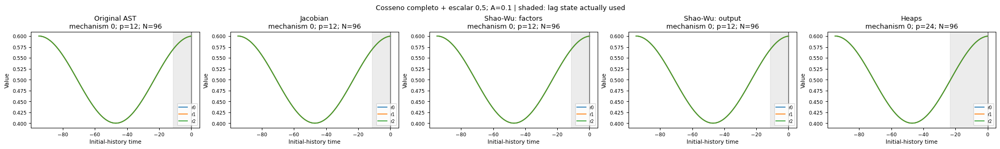

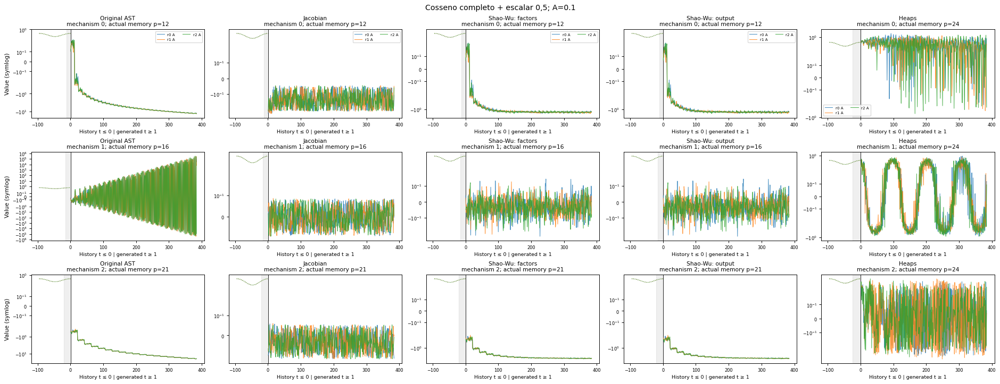

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0093
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0094
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0097
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0088
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0260


In [53]:
scale = 0.1
block = 'Cosseno completo + escalar 0,5; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

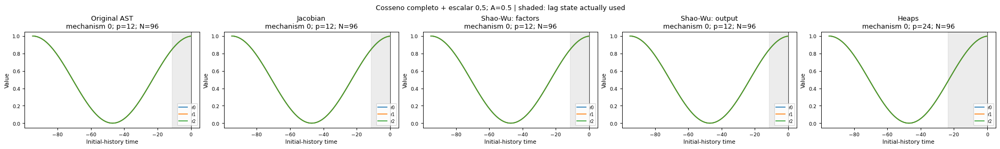

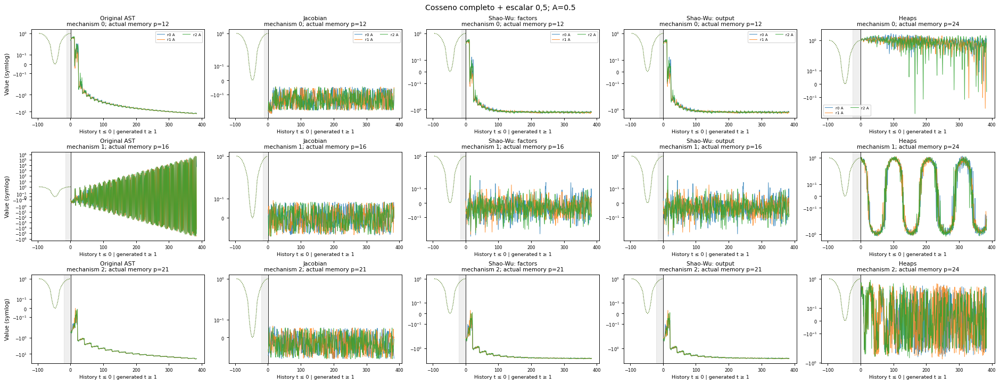

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0065
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0095
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0087
11,Shao-Wu: output,36,0.0000,8.3333,38.8889,16.6667,12,24,0.0097
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0267


In [54]:
scale = 0.5
block = 'Cosseno completo + escalar 0,5; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


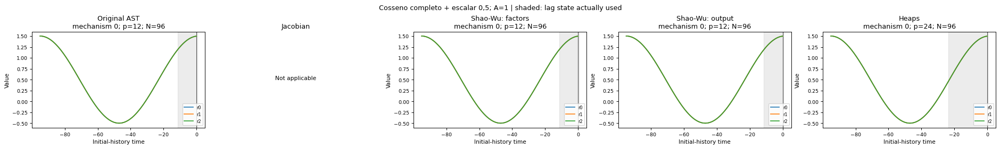

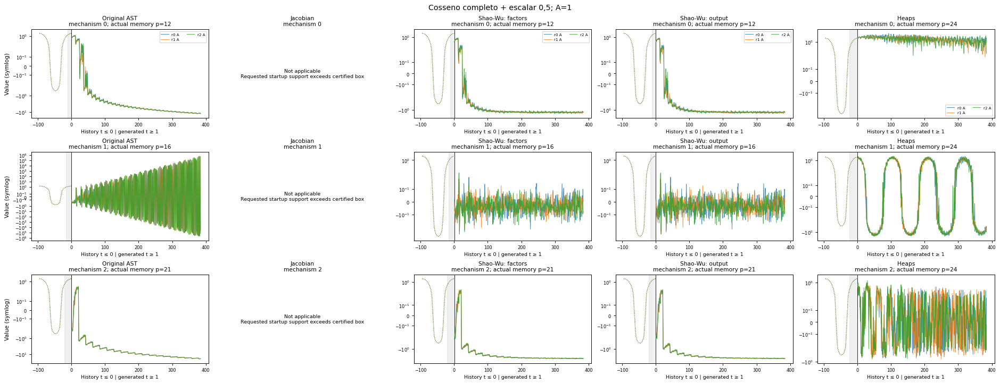

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0067
5,Shao-Wu: factors,36,0.0000,13.8889,44.4444,16.6667,12,24,0.0096
8,Shao-Wu: output,36,0.0000,8.3333,44.4444,22.2222,12,24,0.0094
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0276


In [55]:
scale = 1.0
block = 'Cosseno completo + escalar 0,5; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


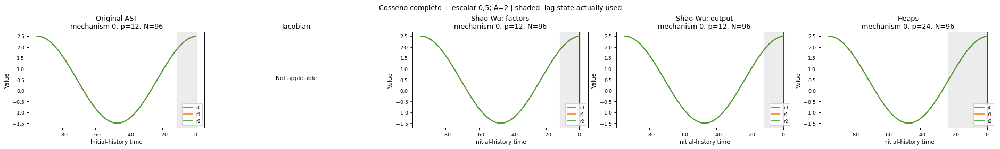

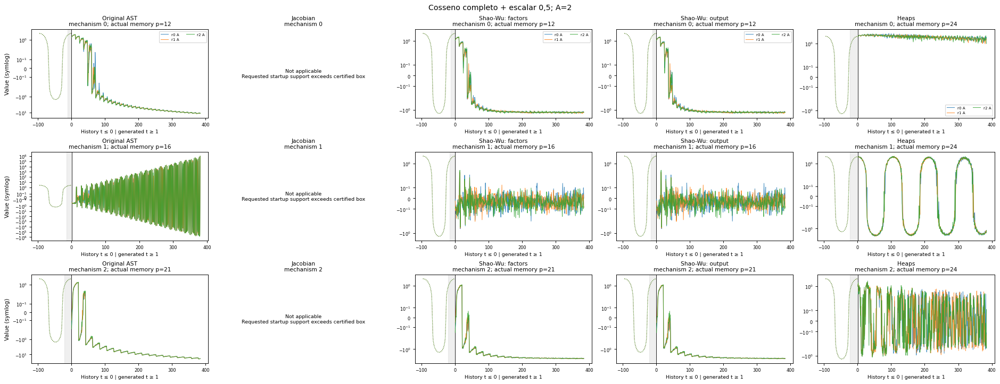

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,5.5556,8.3333,0.0000,12,24,0.0067
5,Shao-Wu: factors,36,0.0000,13.8889,44.4444,16.6667,12,24,0.0099
8,Shao-Wu: output,36,0.0000,8.3333,44.4444,22.2222,12,24,0.0088
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0280


In [56]:
scale = 2.0
block = 'Cosseno completo + escalar 0,5; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


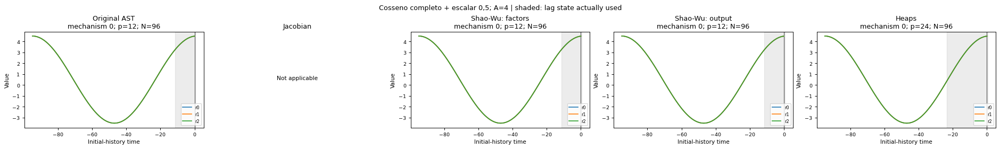

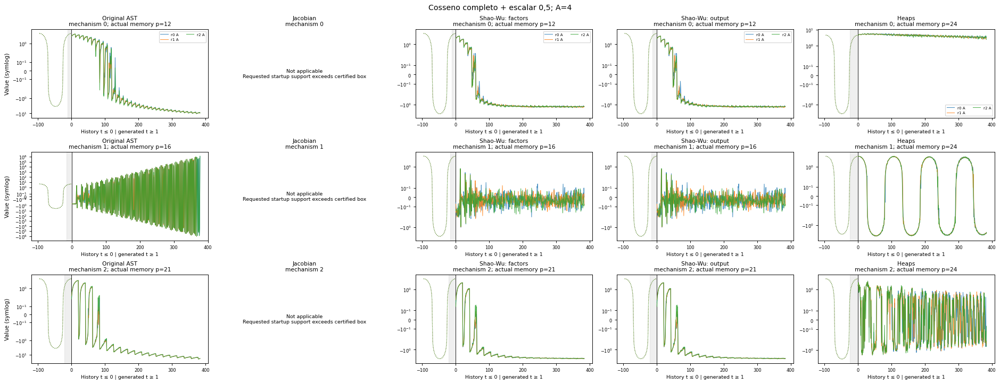

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,5.5556,8.3333,0.0000,12,24,0.0066
5,Shao-Wu: factors,36,0.0000,13.8889,44.4444,16.6667,12,24,0.0089
8,Shao-Wu: output,36,0.0000,8.3333,44.4444,22.2222,12,24,0.0084
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0259


In [57]:
scale = 4.0
block = 'Cosseno completo + escalar 0,5; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 1.0), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

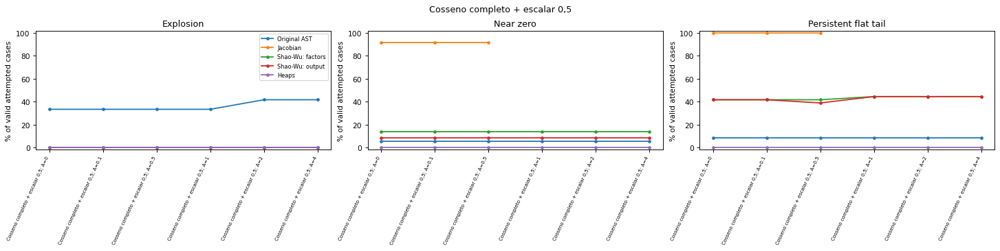

In [58]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno completo + escalar 0,5')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 10. Cosseno metade + escalar 0,5

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

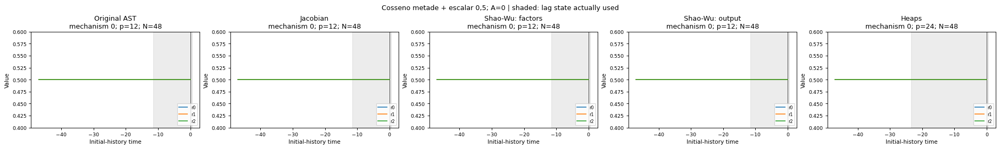

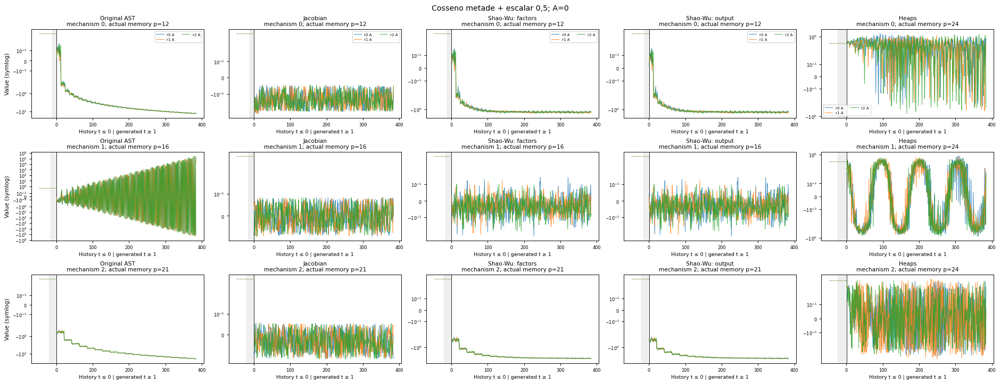

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0087
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0118
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0130
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0089
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0313


In [59]:
scale = 0.0
block = 'Cosseno metade + escalar 0,5; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

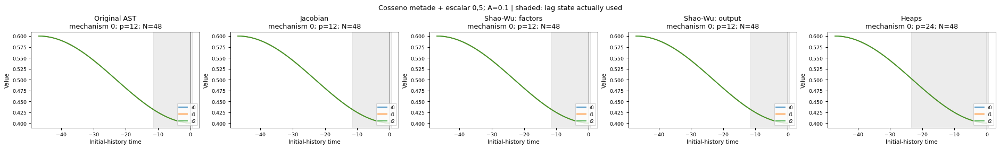

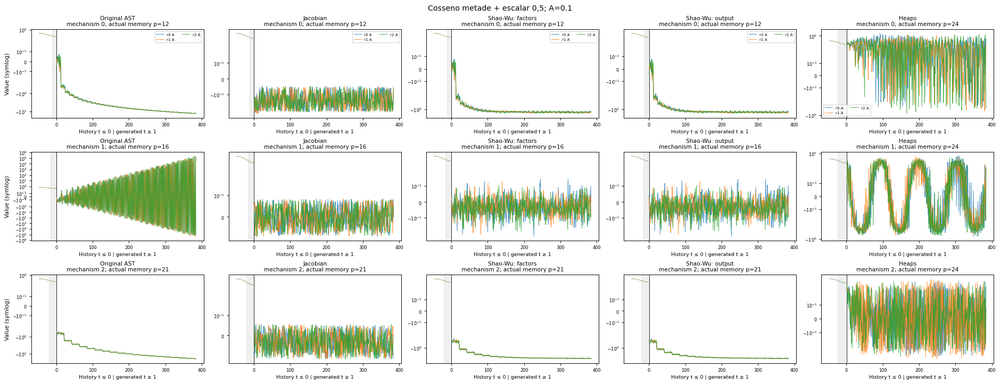

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0080
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0108
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0100
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0100
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0305


In [60]:
scale = 0.1
block = 'Cosseno metade + escalar 0,5; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

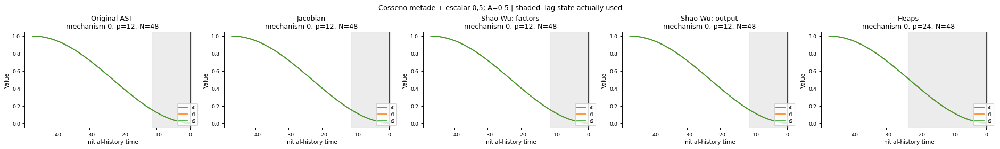

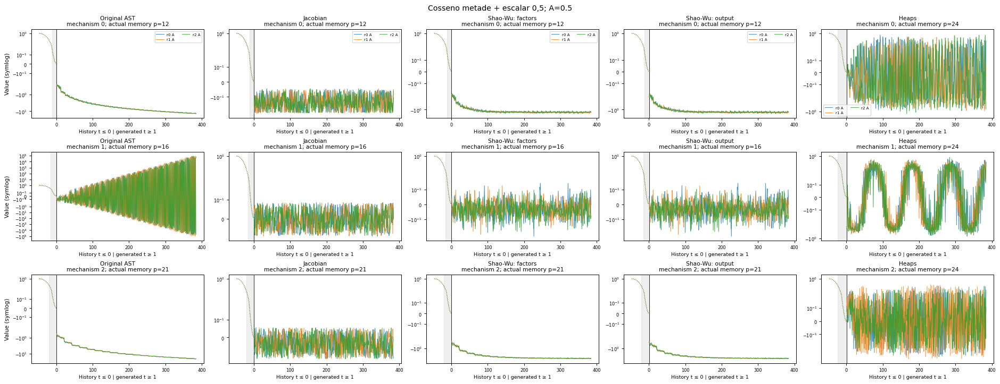

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0080
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0115
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0105
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0095
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0298


In [61]:
scale = 0.5
block = 'Cosseno metade + escalar 0,5; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


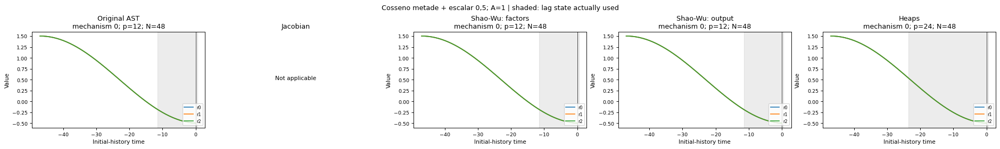

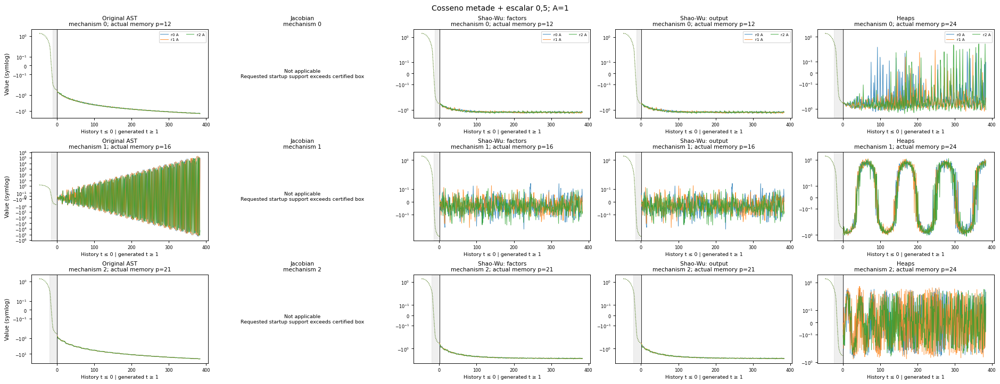

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0085
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0103
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0093
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0291


In [62]:
scale = 1.0
block = 'Cosseno metade + escalar 0,5; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


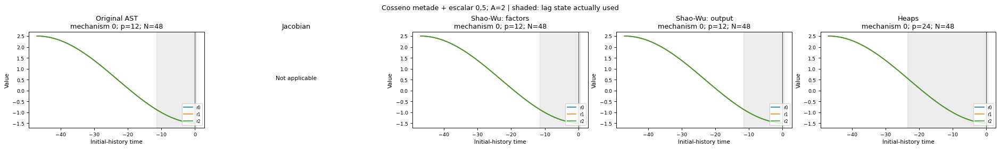

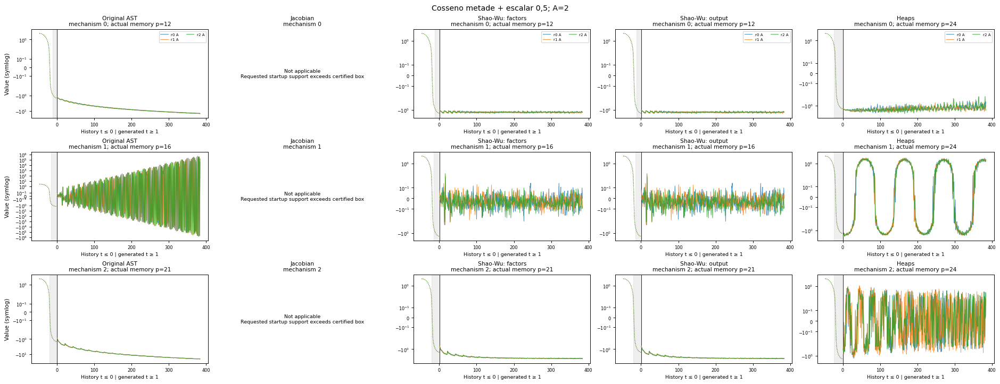

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0082
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0101
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0101
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0296


In [63]:
scale = 2.0
block = 'Cosseno metade + escalar 0,5; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


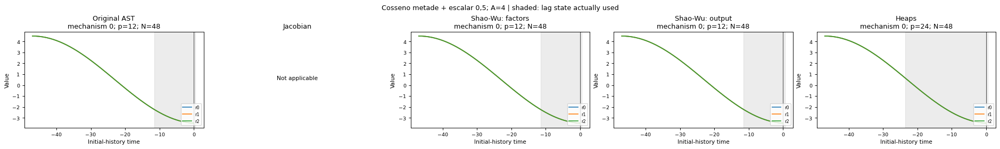

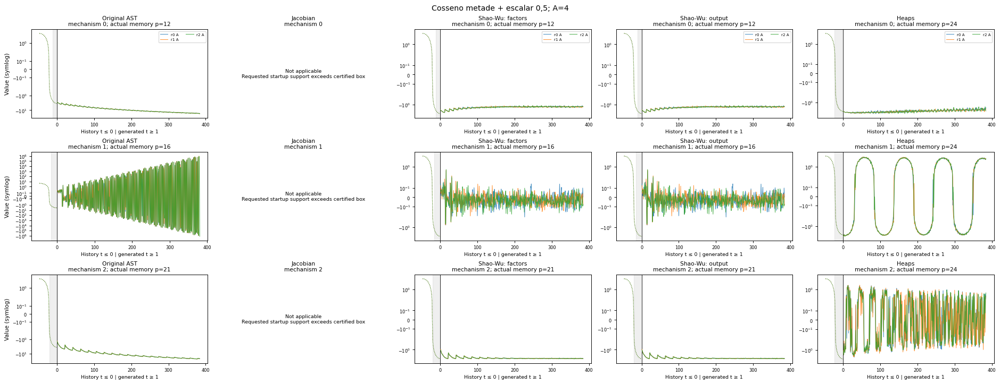

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,41.6667,5.5556,8.3333,0.0000,12,24,0.0083
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0103
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0102
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0288


In [64]:
scale = 4.0
block = 'Cosseno metade + escalar 0,5; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.5), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

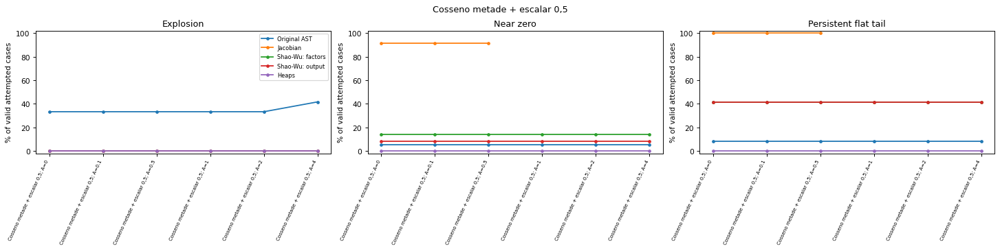

In [65]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno metade + escalar 0,5')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## 11. Cosseno quarto + escalar 0,5

A escala altera a amplitude inicial. Nos cossenos deslocados, o escalar +0,5 permanece fixo. Escalas: 0; 0,1; 0,5; 1; 2; 4. As combinações fora da caixa do Jacobiano são identificadas antes de simular.

### Escala 0

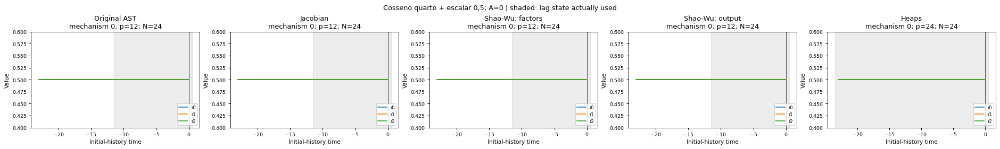

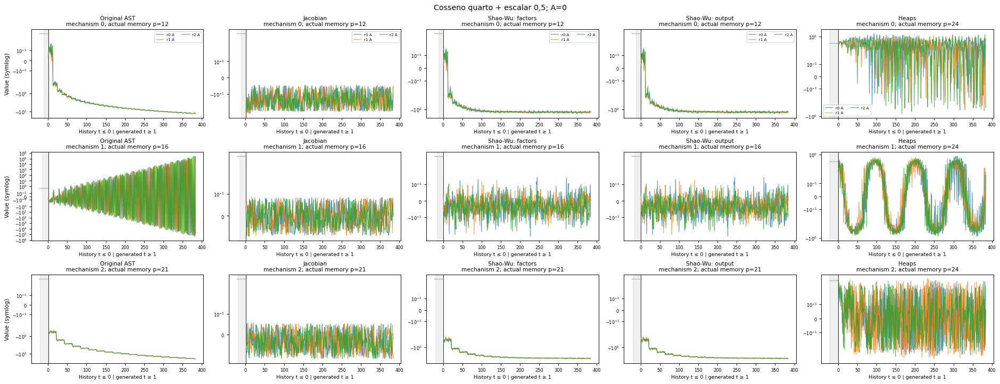

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0084
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0104
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0096
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0098
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0307


In [66]:
scale = 0.0
block = 'Cosseno quarto + escalar 0,5; A=0'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.1

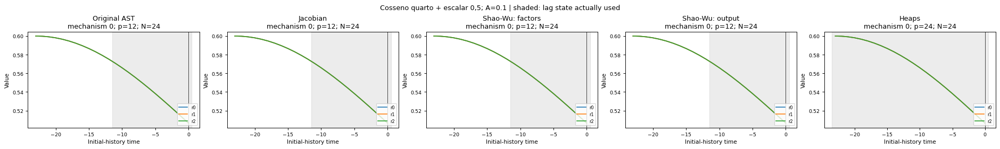

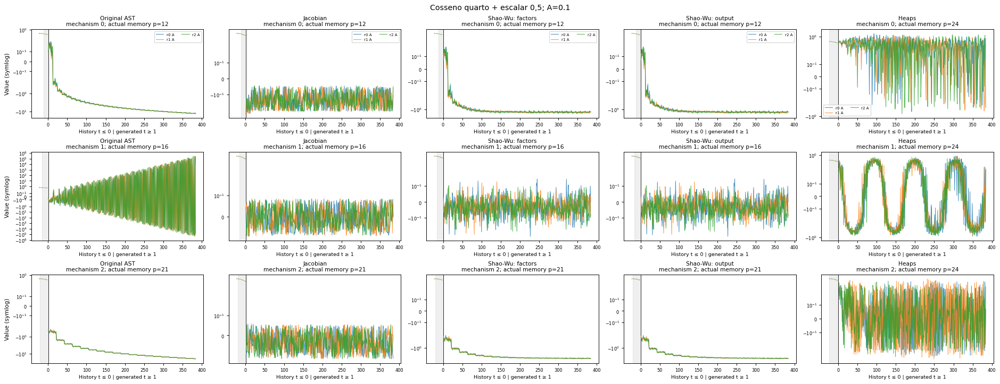

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0079
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0104
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0111
11,Shao-Wu: output,36,0.0000,8.3333,41.6667,13.8889,12,24,0.0105
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0297


In [67]:
scale = 0.1
block = 'Cosseno quarto + escalar 0,5; A=0.1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 0.5

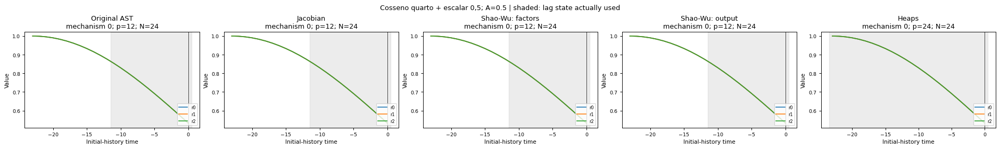

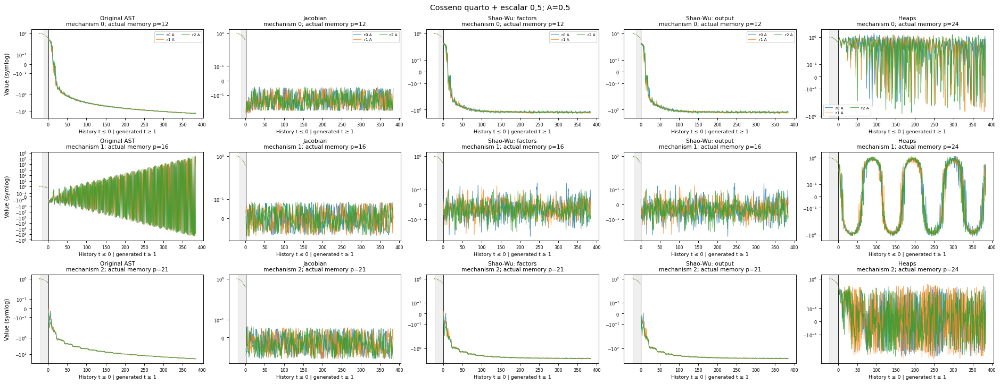

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0083
5,Jacobian,36,0.0000,91.6667,100.0000,0.0000,12,24,0.0149
8,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0129
11,Shao-Wu: output,36,0.0000,8.3333,36.1111,13.8889,12,24,0.0100
14,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0348


In [68]:
scale = 0.5
block = 'Cosseno quarto + escalar 0,5; A=0.5'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 1

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


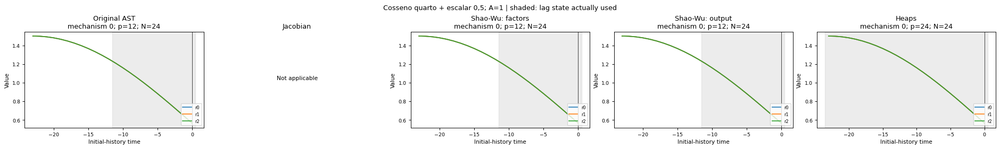

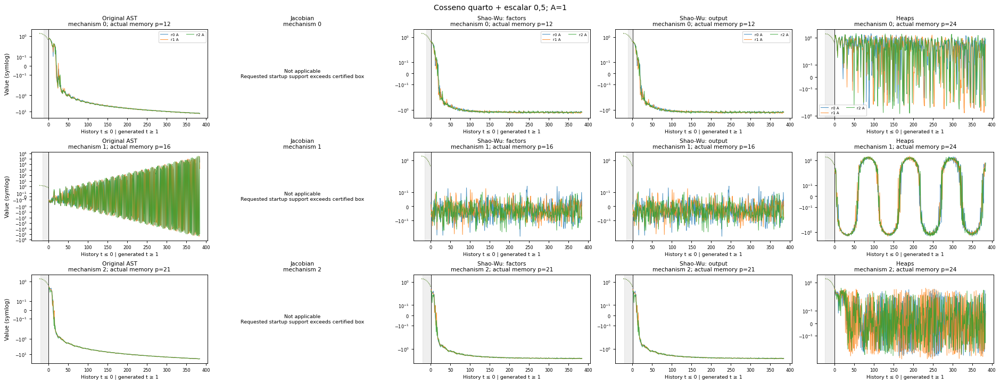

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0067
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0100
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0104
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0288


In [69]:
scale = 1.0
block = 'Cosseno quarto + escalar 0,5; A=1'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 2

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


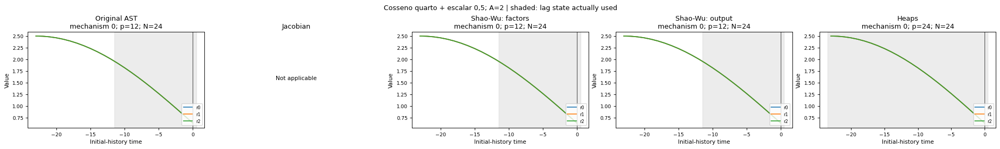

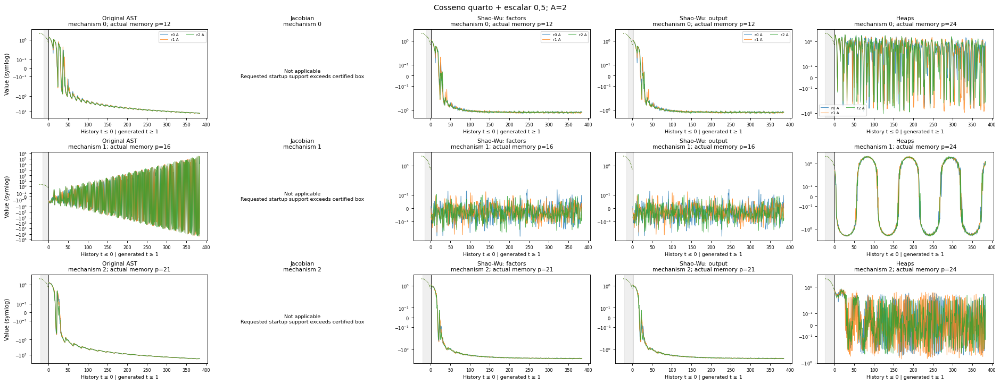

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0075
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0106
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0099
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0285


In [70]:
scale = 2.0
block = 'Cosseno quarto + escalar 0,5; A=2'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

### Escala 4

,method,reason,skipped_trajectories
0,Jacobian,Requested startup support exceeds certified box,36


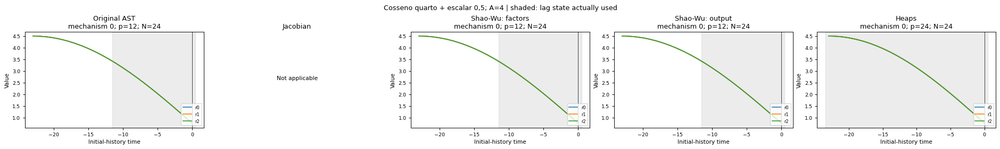

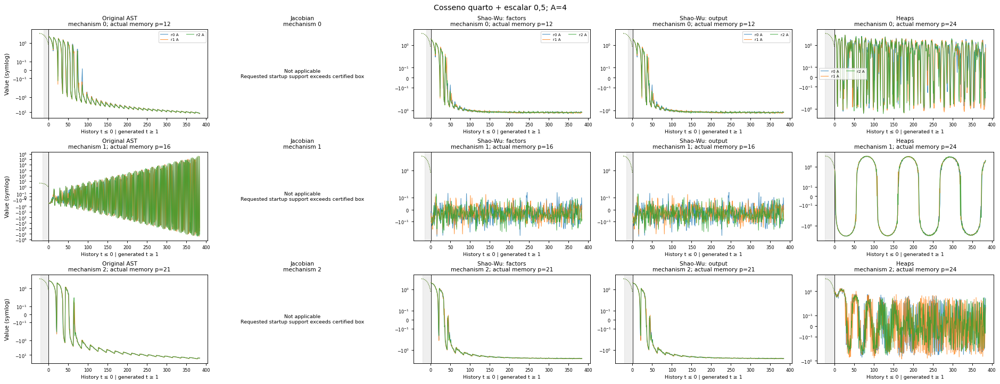

,method,trajectories,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,minimum_actual_lag,maximum_actual_lag,mean_simulation_seconds
2,Original AST,36,33.3333,5.5556,8.3333,0.0000,12,24,0.0075
5,Shao-Wu: factors,36,0.0000,13.8889,41.6667,13.8889,12,24,0.0096
8,Shao-Wu: output,36,0.0000,8.3333,41.6667,19.4444,12,24,0.0090
11,Heaps,36,0.0000,0.0000,0.0000,0.0000,24,24,0.0292


In [71]:
scale = 4.0
block = 'Cosseno quarto + escalar 0,5; A=4'
result = show_condition(block, HistorySpec(block, 'cosine', scale, 0.5, 96, 0.25), cyclic_config(24), overview=False)

**O que foi feito:** Avaliamos a mesma condição nos quatro geradores e exibimos o histórico e a continuação. A tabela conserva as falhas no denominador e explicita as restrições do Jacobiano.

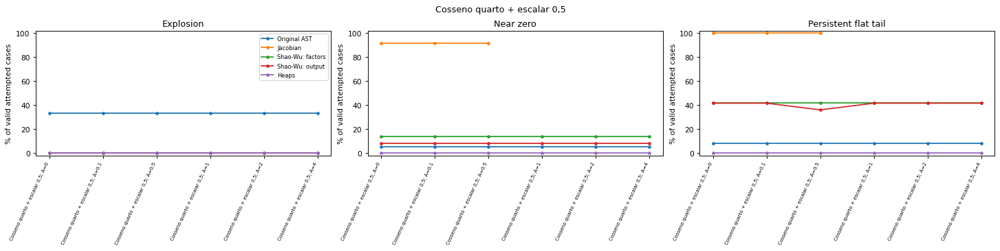

In [72]:
section_summary = pd.concat(SUMMARY_BLOCKS[-6:], ignore_index=True)
plot_condition_summary(section_summary, 'Cosseno quarto + escalar 0,5')
plt.show()

**O que foi feito:** As curvas comparam a resposta de cada método à mudança de escala. Pontos ausentes correspondem às condições não aplicáveis, não a uma taxa zero.

## Resultados consolidados: tabelas por horizonte

Cada linha conserva seu tipo de inicialização, método e tamanho de amostra. As condições não aplicáveis aparecem em tabela própria. Os tempos de simulação referem-se à chamada completa de até 384 passos, com parada na primeira explosão.

In [73]:
pd.set_option("display.max_rows", None)
FINAL_COLUMNS = ['block', 'method', 'trajectories', 'explosions', 'explosions_pct', 'near_zero_pct', 'persistent_flat_pct', 'flat_nonzero_pct', 'amplitude_decline_pct', 'minimum_actual_lag', 'maximum_actual_lag', 'mean_initialization_seconds', 'mean_simulation_seconds']
SUMMARY = pd.concat(SUMMARY_BLOCKS, ignore_index=True)
SKIPPED = pd.concat(SKIPPED_BLOCKS, ignore_index=True) if SKIPPED_BLOCKS else pd.DataFrame()
for horizon in CONFIG.horizons:
    display(Markdown(f"### Horizonte {horizon}"))
    columns = FINAL_COLUMNS
    display(SUMMARY.loc[SUMMARY.horizon == horizon, columns].round(4))
display(Markdown("### Condições fora do domínio de aplicação"))
if SKIPPED.empty:
    display(Markdown("Todas as condições declaradas foram executadas."))
else:
    display(SKIPPED.groupby(["block", "method", "reason"], sort=False).skipped_trajectories.sum().reset_index())


### Horizonte 96

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
0,zero,Original AST,96,20,20.8333,13.5417,17.7083,0.0000,0.0000,1,12,0.0000,0.0055
3,zero,Jacobian,96,0,0.0000,44.7917,98.9583,36.4583,0.0000,1,12,0.0000,0.0105
6,zero,Shao-Wu: factors,96,0,0.0000,17.7083,47.9167,19.7917,0.0000,1,12,0.0000,0.0096
9,zero,Shao-Wu: output,96,0,0.0000,17.7083,46.8750,22.9167,0.0000,1,12,0.0000,0.0105
12,zero,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0141
15,Constante positiva; A=0,Original AST,96,20,20.8333,13.5417,17.7083,0.0000,0.0000,1,12,0.0000,0.0073
18,Constante positiva; A=0,Jacobian,96,0,0.0000,44.7917,98.9583,36.4583,0.0000,1,12,0.0000,0.0131
21,Constante positiva; A=0,Shao-Wu: factors,96,0,0.0000,17.7083,47.9167,19.7917,0.0000,1,12,0.0000,0.0097
24,Constante positiva; A=0,Shao-Wu: output,96,0,0.0000,17.7083,46.8750,22.9167,0.0000,1,12,0.0000,0.0100
27,Constante positiva; A=0,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0138


### Horizonte 192

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
1,zero,Original AST,96,47,48.9583,11.4583,16.6667,2.0833,0.0000,1,12,0.0000,0.0055
4,zero,Jacobian,96,0,0.0000,45.8333,97.9167,33.3333,0.0000,1,12,0.0000,0.0105
7,zero,Shao-Wu: factors,96,0,0.0000,23.9583,61.4583,27.0833,0.0000,1,12,0.0000,0.0096
10,zero,Shao-Wu: output,96,0,0.0000,19.7917,58.3333,30.2083,0.0000,1,12,0.0000,0.0105
13,zero,Heaps,96,0,0.0000,35.4167,37.5000,0.0000,1.0417,1,12,0.0000,0.0141
16,Constante positiva; A=0,Original AST,96,47,48.9583,11.4583,16.6667,2.0833,0.0000,1,12,0.0000,0.0073
19,Constante positiva; A=0,Jacobian,96,0,0.0000,45.8333,97.9167,33.3333,0.0000,1,12,0.0000,0.0131
22,Constante positiva; A=0,Shao-Wu: factors,96,0,0.0000,23.9583,61.4583,27.0833,0.0000,1,12,0.0000,0.0097
25,Constante positiva; A=0,Shao-Wu: output,96,0,0.0000,19.7917,58.3333,30.2083,0.0000,1,12,0.0000,0.0100
28,Constante positiva; A=0,Heaps,96,0,0.0000,35.4167,37.5000,0.0000,1.0417,1,12,0.0000,0.0138


### Horizonte 384

,block,method,trajectories,explosions,explosions_pct,near_zero_pct,persistent_flat_pct,flat_nonzero_pct,amplitude_decline_pct,minimum_actual_lag,maximum_actual_lag,mean_initialization_seconds,mean_simulation_seconds
2,zero,Original AST,96,47,48.9583,10.4167,15.6250,0.0000,0.0000,1,12,0.0000,0.0055
5,zero,Jacobian,96,0,0.0000,46.8750,100.0000,35.4167,0.0000,1,12,0.0000,0.0105
8,zero,Shao-Wu: factors,96,0,0.0000,18.7500,59.3750,27.0833,0.0000,1,12,0.0000,0.0096
11,zero,Shao-Wu: output,96,0,0.0000,16.6667,56.2500,30.2083,0.0000,1,12,0.0000,0.0105
14,zero,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0141
17,Constante positiva; A=0,Original AST,96,47,48.9583,10.4167,15.6250,0.0000,0.0000,1,12,0.0000,0.0073
20,Constante positiva; A=0,Jacobian,96,0,0.0000,46.8750,100.0000,35.4167,0.0000,1,12,0.0000,0.0131
23,Constante positiva; A=0,Shao-Wu: factors,96,0,0.0000,18.7500,59.3750,27.0833,0.0000,1,12,0.0000,0.0097
26,Constante positiva; A=0,Shao-Wu: output,96,0,0.0000,16.6667,56.2500,30.2083,0.0000,1,12,0.0000,0.0100
29,Constante positiva; A=0,Heaps,96,0,0.0000,38.5417,38.5417,0.0000,0.0000,1,12,0.0000,0.0138


### Condições fora do domínio de aplicação

,block,method,reason,skipped_trajectories
0,Constante positiva; A=2,Jacobian,Requested startup support exceeds certified box,96
1,Constante positiva; A=4,Jacobian,Requested startup support exceeds certified box,96
2,Constante negativa; A=2,Jacobian,Requested startup support exceeds certified box,96
3,Constante negativa; A=4,Jacobian,Requested startup support exceeds certified box,96
4,Uniforme aleatório; A=2,Jacobian,Requested startup support exceeds certified box,96
5,Uniforme aleatório; A=4,Jacobian,Requested startup support exceeds certified box,96
6,Histórico estacionário com escala; A=0,Original AST,Joint stationary initializer unavailable,96
7,Histórico estacionário com escala; A=0,Jacobian,Joint stationary initializer unavailable,96
8,Histórico estacionário com escala; A=0,Shao-Wu: factors,Joint stationary initializer unavailable,96
9,Histórico estacionário com escala; A=0,Shao-Wu: output,Joint stationary initializer unavailable,96


**O que foi feito:** Reunimos as métricas de todos os casos executados, sem somar grupos com condições diferentes. As exclusões indicam limitações de aplicação do método.

### Registro completo do experimento

Esta única célula reúne pergunta, hipótese, configurações, fórmulas, sementes, proveniência, métricas, síntese científica e comando de reprodução.

In [74]:
import os
def git_output(*args):
    return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()

last = SUMMARY[SUMMARY.horizon == max(CONFIG.horizons)]
metrics = ["pair_explosion_pct", "forgotten_pct_all_pairs"] if STUDY == "forgetting" else [
    "explosions_pct", "near_zero_pct", "persistent_flat_pct"]
lines = []
for method, block in last.groupby("method", sort=False):
    values = "; ".join(f"{m}: {block[m].min():.2f}% a {block[m].max():.2f}%" for m in metrics)
    lines.append(f"- **{method}:** {values}.")
scientific_summary = "\n".join(lines) + (
    "\n\nOs intervalos acima são mínimos e máximos descritivos entre condições. "
    "Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio "
    "ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações "
    "determinam a continuação. A comparação de lags também reflete as diferentes construções "
    "dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados."
)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted((ROOT / "src" / "tsfmxai").rglob("*.py"))}
record = {
    "research_question": QUESTION,
    "hypothesis": HYPOTHESIS,
    "design": "Cada seção é um tipo de inicialização; dentro dela comparamos as quatro famílias (cinco variantes).",
    "conditions": DECLARATIONS,
    "generator_banks": [{"configuration": asdict(c),
                         "generator_configurations": {g: asdict(v) for g, v in generator_configs(c).items()},
                         "formulas": {g: [m.formulas if hasattr(m, 'formulas') else [m.formula]
                                           for m in mechanisms] for g, mechanisms in banks.items()}}
                        for c, banks in BANKS.items()],
    "seeds": {"mechanism_root": CONFIG.mechanism_seed, "trajectory_root": CONFIG.trajectory_seed,
              "mechanisms": "derive_sample_seed(mechanism_root, index)",
              "streams": "SeedSequence([trajectory_root, mechanism_index, trajectory_index]).spawn(3)",
              "stream_names": ["unit_history", "future_innovations", "stationary_history"],
              "pairing": "Exact future innovation arrays reused across conditions within each mechanism/trajectory."},
    "provenance": {"source_sha256": source_hashes, "python": sys.version, "platform": platform.platform(),
                   "packages": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "nbformat", "nbclient")},
                   "numerical_threads": 1, "execution_schedule": os.environ.get("TSFMXAI_EXECUTION_SCHEDULE", "Not specified by runner")},
    "metrics": json.loads(SUMMARY.to_json(orient="records")),
    "unsupported_cases": json.loads(SKIPPED.to_json(orient="records")),
    "scientific_summary": scientific_summary,
    "reproduction_command_from_repository_root": (
        ".venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        f"experiments/time_series_initialization/{NOTEBOOK_NAME} --ExecutePreprocessor.timeout=3600"),
    "references": ["Heaps (2023): https://arxiv.org/pdf/2004.09455",
                   "Shao and Wu (2007), Theorem 5.1: https://arxiv.org/pdf/math/0611029",
                   "Project report, generator-specific guarantees and startup restrictions."],
}
display(Markdown("**Síntese científica desta execução**\n\n" + scientific_summary))
display(JSON(record, expanded=False))


**Síntese científica desta execução**

- **Original AST:** explosions_pct: 33.33% a 53.12%; near_zero_pct: 5.56% a 10.42%; persistent_flat_pct: 8.33% a 15.62%.
- **Jacobian:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 46.88% a 91.67%; persistent_flat_pct: 100.00% a 100.00%.
- **Shao-Wu: factors:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 13.89% a 18.75%; persistent_flat_pct: 41.67% a 59.38%.
- **Shao-Wu: output:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 8.33% a 16.67%; persistent_flat_pct: 36.11% a 56.25%.
- **Heaps:** explosions_pct: 0.00% a 0.00%; near_zero_pct: 0.00% a 38.54%; persistent_flat_pct: 0.00% a 38.54%.

Os intervalos acima são mínimos e máximos descritivos entre condições. Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações determinam a continuação. A comparação de lags também reflete as diferentes construções dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados.

<IPython.core.display.JSON object>

**O que foi feito:** O registro permite reproduzir a execução e recuperar as condições exatas que produziram cada linha da tabela. Todos os resultados ficam neste notebook.